# Public Data Indicators for Ex-Ante Financial Control: Procedure BG-RRP-1.015 "School STEM Environment"

**Element 2 (E2)** of the Financial Controller qualification thesis on *"Ex-Ante Control for Legality and Fraud and Irregularity Indicators in the Award and Expenditure of Funds under Procedure BG-RRP-1.015 'School STEM Environment'"*.

**Methodological safeguard:** A statistical indicator in public procurement records is **not** a proven legal violation. Indicators identify measurable patterns before commitment that require documentary verification against internal financial control files (Element 3) and preventive checklist controls (Element 4). In accordance with public registry rules, legal entity and school names and EIK/Bulstat identifiers are preserved throughout tables and analyses, while sole-trader (`ЕТ`) and natural-person names are redacted.

**Author:** Valeriy Beluhov.

## 1. Purpose, Scope, Inputs, and Relational Database Preparation

This study measures ex-ante control indicators verifiable prior to commitment in public data for procedure `BG-RRP-1.015` (National Recovery and Resilience Plan) under Art. 13(3) items 1 and 3 of the Financial Management and Control in the Public Sector Act (FMCPSA), Ministry of Finance Guidelines `ZMF-184/06.03.2020`, and Arts. 17, 20, and 21 of the Public Procurement Act (PPA).

**Working Hypothesis (H2):** Pre-specified decision rule — confirmed if at least two of the three contract-level indicators (`predated`, `split_30d`, `regime_mismatch`) exhibit a lower 95% Wilson confidence bound exceeding **5%** (`0.05`) across participating schools with contracts (`N = 2,222`).

**Primary Inputs (read-only):**
- `openData.xml` and `openData.xsd` (`EXTRACTION_DATE = "2026-09-10"`): ISUN 2020 open data export hashed in `data/MANIFEST.csv`;
- Upstream Element 1 (`adfi-violations-classification@c9bd90d`): `adfi_reports_meta.csv`, `adfi_classification.csv`, `adfi_classification_verbatim.csv`, `classifier_classes.csv`.


In [1]:
from __future__ import annotations

import csv
import math
import re
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import sparse, stats
from statsmodels.discrete.discrete_model import Poisson

EXTRACTION_DATE = "2026-09-10"
PROCEDURE_PREFIX = "BG-RRP-1.015"
EUR_BGN = 1.95583
VAT_FACTOR = 1.20
RATIO_TOLERANCE = 0.03
REGIME_1_CUTOFF = "2023-12-31"
EURO_FROM = "2026-01-01"
RNG_STATE = 2026
WILSON_Z = 1.95996

DATA_DIR = Path("data")
DERIVED_DIR = DATA_DIR / "derived"
FIG_DIR = Path("fig")
DERIVED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
})

conclusions_log = []


def record_conclusion(part, question, measure, value, interval_low="", interval_high="", interval_method="none", decision="none"):
    """Append one verified quantitative metric row for conclusions_summary.csv."""
    conclusions_log.append({
        "part": str(part),
        "question": str(question),
        "measure": str(measure),
        "value": str(value),
        "interval_low": "" if interval_low == "" else str(interval_low),
        "interval_high": "" if interval_high == "" else str(interval_high),
        "interval_method": str(interval_method),
        "decision": str(decision),
    })


def flush_conclusions():
    """Persist conclusions_summary.csv using Element 1 semicolon-delimited format."""
    df_out = pd.DataFrame(
        conclusions_log,
        columns=["part", "question", "measure", "value", "interval_low", "interval_high", "interval_method", "decision"],
    )
    df_out.to_csv(DERIVED_DIR / "conclusions_summary.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")
    return df_out


def wilson_ci(k: int, n: int, z: float = WILSON_Z):
    """Return (proportion, lower_95, upper_95) using the Wilson score interval."""
    if n <= 0:
        return 0.0, 0.0, 0.0
    p = k / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = z * math.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / denom
    return p, max(0.0, center - half), min(1.0, center + half)


def bh_fdr(p_values):
    """Compute Benjamini-Hochberg adjusted q-values."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p, kind="stable")
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    q = np.empty_like(p)
    q[order] = np.minimum(np.minimum.accumulate(scaled[::-1])[::-1], 1.0)
    return q


In [2]:
isun_projects = pd.read_csv(DATA_DIR / "isun_projects.csv", dtype=str, keep_default_na=False)
for col in ("total_value", "actually_paid_amount"):
    isun_projects[col] = pd.to_numeric(isun_projects[col])

isun_contracts = pd.read_csv(DATA_DIR / "isun_contracts.csv", dtype=str, keep_default_na=False)
for col in ("amount_raw", "subcontractors_count"):
    isun_contracts[col] = pd.to_numeric(isun_contracts[col])
isun_contracts["subcontractors_count"] = isun_contracts["subcontractors_count"].astype(int)

isun_entities = pd.read_csv(DATA_DIR / "isun_entities.csv", dtype=str, keep_default_na=False)
schools_register = pd.read_csv(DATA_DIR / "schools_register.csv", dtype=str, keep_default_na=False)
for col in schools_register.columns[9:]:
    schools_register[col] = pd.to_numeric(schools_register[col])

adfi_meta = pd.read_csv(DATA_DIR / "adfi_reports_meta.csv", sep=";", dtype=str, keep_default_na=False)
adfi_cls = pd.read_csv(DATA_DIR / "adfi_classification.csv", sep=",", dtype=str, keep_default_na=False)
adfi_verb = pd.read_csv(DATA_DIR / "adfi_classification_verbatim.csv", sep=";", dtype=str, keep_default_na=False)
classifier_classes = pd.read_csv(DATA_DIR / "classifier_classes.csv", sep=";", dtype=str, keep_default_na=False)

contracts = pd.read_csv(DERIVED_DIR / "contracts.csv", dtype=str, keep_default_na=False)
for col in ("contract_row", "delta_t_days", "amount_raw", "amount_eur_incl_vat", "amount_eur_excl_vat", "amount_bgn_excl_vat", "paid_alloc_eur_incl_vat", "subcontractors_count"):
    contracts[col] = pd.to_numeric(contracts[col])

schools = pd.read_csv(DERIVED_DIR / "schools.csv", dtype=str, keep_default_na=False)
for col in ("projects_count", "contracts_count", "register_budget_bgn_incl_vat", "contracted_eur_incl_vat", "contracted_eur_excl_vat", "paid_eur_incl_vat"):
    schools[col] = pd.to_numeric(schools[col])
for col in ("flag_predated", "flag_split_30d", "flag_regime_mismatch", "flag_level1", "flag_bunching_50k"):
    schools[col] = schools[col] == "True"

project_classes = pd.read_csv(DERIVED_DIR / "project_classes.csv", dtype=str, keep_default_na=False)
for col in ("total_value", "actually_paid_amount", "contract_sum_raw", "register_budget_bgn_incl_vat", "register_budget_eur_incl_vat", "paid_eur_incl_vat"):
    project_classes[col] = pd.to_numeric(project_classes[col])

normalized_totals = pd.read_csv(DERIVED_DIR / "normalized_totals.csv")
flags_tbl = pd.read_csv(DERIVED_DIR / "forensic_risk_flags.csv", dtype=str, keep_default_na=False)
for col in ("contract_row", "amount_raw", "amount_eur_excl_vat", "amount_bgn_excl_vat", "threshold_bgn_excl_vat"):
    flags_tbl[col] = pd.to_numeric(flags_tbl[col])
for col in ("flag_predated", "flag_split_30d", "flag_same_day_sub", "flag_regime_mismatch", "flag_level1", "flag_bunching_30k", "flag_bunching_50k", "flag_bunching_80k"):
    flags_tbl[col] = flags_tbl[col] == "True"

assert len(isun_projects) == 2228
assert len(isun_contracts) == 11128
assert len(contracts) == 11128
assert len(schools) == 2222
assert "vendor_role" not in contracts.columns
assert "name" in isun_entities.columns and "vendor_name" in contracts.columns and "school_name" in schools.columns
assert not any("zdoi" in c.lower() for c in schools.columns)

print(f"Loaded {len(isun_projects):,} projects, {len(isun_contracts):,} contracts, {len(isun_entities):,} entities, {len(schools_register):,} register institutions.")
print(f"Loaded {len(adfi_meta):,} ADFI reports ({len(adfi_cls):,} classification rows) and {len(schools):,} STEM schools with contracts.")


Loaded 2,228 projects, 11,128 contracts, 3,973 entities, 2,271 register institutions.
Loaded 560 ADFI reports (1,824 classification rows) and 2,222 STEM schools with contracts.


## 2. Currency and VAT Normalization and Verification of Structural Invariants

ISUN 2020 mixes legacy BGN entries with post-euro entries, with or without 20% VAT. The project is the unit of normalization. The sum of its contracts is divided by the project's budget ceiling in the `BG-RRP-1.015` register (BGN incl. VAT), and the ratio is matched, within a 3% tolerance, to one of four canonical values: `1.0`, `1/1.2`, `1/1.95583`, `1/(1.95583*1.2)`. The match gives the currency and the VAT basis, and every contract of the project inherits both.

Three rules complete the procedure. Contracts signed on or after 2026-01-01 are taken as EUR. Where the ceiling ratio is inconclusive, the currency is inferred from the ratio of paid to contracted amounts, and EUR is assumed when that ratio is inconclusive too. Where the VAT basis stays undetermined, the dominant basis (`incl_vat`) is assumed.

Both bases are needed for financial control:
- **`amount_eur_incl_vat`**: the basis for internal budgetary ceiling checks prior to commitment under Art. 13(3), item 3 FMCPSA;
- **`amount_bgn_excl_vat` / `amount_eur_excl_vat`**: the basis for the procurement thresholds of Art. 20 PPA (`30,000`, `50,000`, `80,000 BGN excl. VAT`). The 20% VAT difference inside `[41,667; 60,000] BGN` decides whether a contract falls below or above the `50,000 BGN` threshold (Class `1.02` in Element 1).

The next cell asserts the structural invariants (counts of projects, schools, contracts, suppliers and register matches, and the agreement of contract sums with the normalized totals) and writes the reconciliation to `data/derived/reconciliation_summary.csv`.

In [3]:
n_projects = len(isun_projects)
n_beneficiaries = project_classes["school_bulstat"].nunique()
n_projects_with_contract = contracts["project_id"].nunique()
n_schools_with_contract = contracts["school_bulstat"].nunique()
n_projects_without_contract = n_projects - n_projects_with_contract
n_contracts = len(contracts)
n_unique_cids = contracts["contract_id"].nunique()
n_duplicate_cids = int(contracts["contract_id"].duplicated().sum())
non_empty_vendors = contracts.loc[contracts["vendor_id"] != "", "vendor_id"]
n_vendors_id = non_empty_vendors.nunique()
n_vendors_eik = contracts.loc[contracts["vendor_eik"] != "", "vendor_eik"].nunique()
n_contracts_no_eik = int((contracts["vendor_eik"] == "").sum())
n_contracts_no_vid = int((contracts["vendor_id"] == "").sum())

total_incl_vat = float(normalized_totals.loc[0, "total_contracted_eur_incl_vat"])
total_excl_vat = float(normalized_totals.loc[0, "total_contracted_eur_excl_vat"])
total_vat_national = round(total_incl_vat - total_excl_vat, 2)
total_paid = float(normalized_totals.loc[0, "total_disbursed_eur_incl_vat"])
total_unpaid = float(normalized_totals.loc[0, "total_unpaid_eur_incl_vat"])
n_default_curr = int(normalized_totals.loc[0, "contracts_currency_by_default"])
n_assumed_vat = int(normalized_totals.loc[0, "contracts_vat_assumed"])
vat_assumed_raw = float(normalized_totals.loc[0, "vat_assumed_amount_raw"])

known_vat_proj = project_classes[project_classes["contract_vat_basis"] != "undetermined"]
incl_share_known = float((known_vat_proj["contract_vat_basis"] == "incl_vat").mean())

assert n_projects == 2228
assert n_beneficiaries == 2227
assert n_projects_with_contract == 2223 and n_projects_without_contract == 5
assert n_schools_with_contract == 2222
assert n_contracts == 11128 and contracts["contract_row"].is_unique
assert n_vendors_id == 1754 and n_vendors_eik == 1732 and n_contracts_no_eik == 46
assert (project_classes["register_match"] == "bulstat").sum() == 2075
assert (project_classes["register_match"] == "name_settlement").sum() == 153
assert abs(contracts["amount_eur_incl_vat"].sum() - total_incl_vat) < 0.02
assert abs(contracts["amount_eur_excl_vat"].sum() - total_excl_vat) < 0.02

reconcil_rows = [
    ("Projects in procedure BG-RRP-1.015", n_projects, "ISUN openData.xml"),
    ("Unique beneficiary schools (register matched)", n_beneficiaries, "One school holds two projects (100% matched)"),
    ("Projects with at least one contract", n_projects_with_contract, "Across 2,222 schools; 5 projects have 0 contracts"),
    ("Contract rows (key: contract_row)", n_contracts, f"{n_duplicate_cids} duplicate contract_id strings"),
    ("Identified suppliers (vendor_id / EIK)", f"{n_vendors_id} / {n_vendors_eik}", f"{n_contracts_no_eik} contracts lack EIK; {n_contracts_no_vid} lacks vendor_id"),
    ("Matched by Bulstat / name+settlement", "2075 / 153", "100% matched against raw MoES register"),
    ("Contracted value incl. VAT (EUR)", f"{total_incl_vat:,.2f}", "Control basis under Art. 13(3)(3) FMCPSA"),
    ("Contracted value excl. VAT (EUR)", f"{total_excl_vat:,.2f}", "EU RRF grant basis; Art. 20 PPA threshold basis"),
    ("National VAT co-financing (EUR)", f"{total_vat_national:,.2f}", "20% VAT component"),
    ("Disbursed payments incl. VAT (EUR)", f"{total_paid:,.2f}", f"{total_paid / total_incl_vat:.2%} of contracted total"),
    ("Unpaid remainder incl. VAT (EUR)", f"{total_unpaid:,.2f}", f"{total_unpaid / total_incl_vat:.2%} open to ex-ante expenditure control"),
    ("Contracts with assumed incl_vat regime", n_assumed_vat, f"Raw sum {vat_assumed_raw:,.2f}; {incl_share_known:.1%} of classified projects are incl_vat"),
]
reconcil_df = pd.DataFrame(reconcil_rows, columns=["invariant", "computed_value", "notes"])
reconcil_df.to_csv(DERIVED_DIR / "reconciliation_summary.csv", index=False, encoding="utf-8", lineterminator="\n")
display(reconcil_df.style.hide(axis="index"))
display(contracts["currency_basis"].value_counts().rename_axis("currency_basis").to_frame("contracts"))

record_conclusion("Section 2", "reconciliation", "projects in BG-RRP-1.015", n_projects)
record_conclusion("Section 2", "reconciliation", "unique beneficiary schools", n_beneficiaries)
record_conclusion("Section 2", "reconciliation", "projects with contract", n_projects_with_contract)
record_conclusion("Section 2", "reconciliation", "schools with contract", n_schools_with_contract)
record_conclusion("Section 2", "reconciliation", "projects without contract", n_projects_without_contract)
record_conclusion("Section 2", "reconciliation", "contracts count", n_contracts)
record_conclusion("Section 2", "reconciliation", "unique contract_id", n_unique_cids)
record_conclusion("Section 2", "reconciliation", "distinct non-empty vendor_id", n_vendors_id)
record_conclusion("Section 2", "reconciliation", "distinct vendor_eik", n_vendors_eik)
record_conclusion("Section 2", "reconciliation", "contracts without vendor_eik", n_contracts_no_eik)
record_conclusion("Section 2", "reconciliation", "total contracted EUR incl VAT", f"{total_incl_vat:.2f}")
record_conclusion("Section 2", "reconciliation", "total contracted EUR excl VAT", f"{total_excl_vat:.2f}")
record_conclusion("Section 2", "reconciliation", "national VAT co-financing EUR", f"{total_vat_national:.2f}")
record_conclusion("Section 2", "reconciliation", "total disbursed EUR incl VAT", f"{total_paid:.2f}")
record_conclusion("Section 2", "reconciliation", "total unpaid remainder EUR incl VAT", f"{total_unpaid:.2f}")
record_conclusion("Section 2", "reconciliation", "unpaid share of contracted value", f"{total_unpaid / total_incl_vat:.6f}")
record_conclusion("Section 2", "reconciliation", "contracts with default currency", n_default_curr)
record_conclusion("Section 2", "reconciliation", "contracts with dominant VAT assumption", n_assumed_vat)
record_conclusion("Section 2", "reconciliation", "assumed VAT raw amount", f"{vat_assumed_raw:.2f}")
record_conclusion("Section 2", "reconciliation", "share of classified projects with incl VAT", f"{incl_share_known:.6f}")
flush_conclusions()
print(f"Currency basis breakdown: {contracts['currency_basis'].value_counts().to_dict()}")


invariant,computed_value,notes
Projects in procedure BG-RRP-1.015,2228,ISUN openData.xml
Unique beneficiary schools (register matched),2227,One school holds two projects (100% matched)
Projects with at least one contract,2223,"Across 2,222 schools; 5 projects have 0 contracts"
Contract rows (key: contract_row),11128,454 duplicate contract_id strings
Identified suppliers (vendor_id / EIK),1754 / 1732,46 contracts lack EIK; 1 lacks vendor_id
Matched by Bulstat / name+settlement,2075 / 153,100% matched against raw MoES register
Contracted value incl. VAT (EUR),"288,593,366.12",Control basis under Art. 13(3)(3) FMCPSA
Contracted value excl. VAT (EUR),"240,494,471.77",EU RRF grant basis; Art. 20 PPA threshold basis
National VAT co-financing (EUR),"48,098,894.35",20% VAT component
Disbursed payments incl. VAT (EUR),"260,070,052.15",90.12% of contracted total


,contracts
currency_basis,
ceiling,5166
default,2221
date,2203
payment,1538


Currency basis breakdown: {'ceiling': 5166, 'default': 2221, 'date': 2203, 'payment': 1538}


## 3. Normative Concept Mapping and Bridge to Element 1 (ADFI Classifier)

Every public-data indicator is operationalized strictly as a control check before commitment under Art. 13(3) items 1 and 3 FMCPSA and linked directly to its corresponding violation classes in Element 1 (`adfi-violations-classification@c9bd90d`). Following the author's statutory specification (Decision 6 and Decision 7), because ISUN records uniform text without distinguishing supplies/services from construction works, all contract-level and bunching evaluations apply the statutory **goods and services thresholds** at the signature date (`30,000 BGN excl. VAT` up to `31.12.2023`; `50,000 BGN excl. VAT` from `01.01.2024`, SG No. 88/20.10.2023). Works limits (`50,000 / 80,000 BGN excl. VAT`) are mapped normatively and shown strictly as visual reference lines in Figure `F2_1`.


In [4]:
cls_summary_e1 = classifier_classes.set_index("class_index")
total_e1_rows = int(pd.to_numeric(classifier_classes["rows_total"]).sum())
total_e1_viol = int(pd.to_numeric(classifier_classes["rows_violation"]).sum())
total_e1_nv = int(pd.to_numeric(classifier_classes["rows_no_violation"]).sum())
assert total_e1_rows == 1824 and total_e1_viol == 1203 and total_e1_nv == 621

# E1 restricted to the ADFI reports on STEM schools of this procedure (school_in_stem in adfi_matches.csv).
adfi_match = pd.read_csv(DERIVED_DIR / "adfi_matches.csv", dtype=str, keep_default_na=False)


def report_norm(key):
    key = re.sub(r"\.md$", "", key)
    return re.sub(r"[^0-9A-Za-zА-Яа-я/\-\[\]]", "", key).replace("Доклад", "").replace("pdf", "")


adfi_match["rk"] = adfi_match["report_key"].map(report_norm)
assert not adfi_match["rk"].duplicated().any()
e1_rows = adfi_cls.assign(rk=adfi_cls["report_id"].map(report_norm)).merge(
    adfi_match[["rk", "school_in_stem", "school_bulstat"]], on="rk", how="left", validate="many_to_one")
assert e1_rows["school_in_stem"].notna().all() and len(e1_rows) == total_e1_rows
e1_rows["is_violation"] = e1_rows["outcome"].str.startswith("violation")
e1_rows["section_no"] = e1_rows["class_index"].map(cls_summary_e1["section_no"])
e1_stem = e1_rows[e1_rows["school_in_stem"] == "True"]
stem_reports = adfi_match[adfi_match["school_in_stem"] == "True"]
n_e1_reports = int(len(stem_reports))
n_e1_schools = int(stem_reports["school_bulstat"].nunique())
n_e1_excluded = int((adfi_match["school_in_stem"] != "True").sum())
stem_e1_rows = int(len(e1_stem))
stem_e1_viol = int(e1_stem["is_violation"].sum())
stem_e1_nv = stem_e1_rows - stem_e1_viol
sec_24_viol = int(e1_stem.loc[e1_stem["section_no"].isin(["2", "3", "4"]), "is_violation"].sum())

sig_dt = pd.to_datetime(contracts["signature_date"])
contracts["regime"] = np.where(sig_dt <= pd.Timestamp(REGIME_1_CUTOFF), 1, 2)
n_reg1 = int((contracts["regime"] == 1).sum())
n_reg2 = int((contracts["regime"] == 2).sum())
assert n_reg1 == 73 and n_reg2 == 11055

def e1_counts(idx_list):
    parts = []
    for ci in idx_list:
        r = e1_stem[e1_stem["class_index"] == ci]
        v = int(r["is_violation"].sum())
        parts.append(f"{ci}: {v} viol / {len(r) - v} no-viol ({r['report_id'].nunique()} reports)")
    return "; ".join(parts)

concepts_rows = [
    {
        "indicator": "predated",
        "bg_term": "Договор преди старта на проекта",
        "control_point": "Ex-ante check before commitment: time eligibility & project start chronology",
        "legal_basis": "Art. 13(3)(3) FMCPSA; ZMF-184/2020 Section IV",
        "threshold_bgn_excl_vat": "N/A (delta_t_days < 0)",
        "e1_classes": "10.01; 10.02; 7.03",
        "e1_findings_summary": e1_counts(["10.01", "10.02", "7.03"]),
    },
    {
        "indicator": "split_30d",
        "bg_term": "Разделяне на поръчки в 30-дневен прозорец",
        "control_point": "Ex-ante check before commitment: anti-splitting aggregation across 30 days (incl. same day)",
        "legal_basis": "Art. 21(14)-(15) & Art. 20(4) PPA; Art. 13(3)(3) FMCPSA",
        "threshold_bgn_excl_vat": "Regime 1 (<=2023-12-31): 30,000 BGN (73 contracts); Regime 2 (>=2024-01-01): 50,000 BGN (11,055 contracts)",
        "e1_classes": "1.01",
        "e1_findings_summary": e1_counts(["1.01"]),
    },
    {
        "indicator": "regime_mismatch",
        "bg_term": "Несъответствие с приложимия праг по Режим 1",
        "control_point": "Ex-ante check before commitment: statutory threshold at signature date",
        "legal_basis": "Art. 17(1) & Art. 20(3)-(4) PPA",
        "threshold_bgn_excl_vat": "30,000 <= value < 50,000 BGN (Regime 1); >=50,000 tracked alongside",
        "e1_classes": "1.02",
        "e1_findings_summary": e1_counts(["1.02"]),
    },
    {
        "indicator": "bunching_50k",
        "bg_term": "Ценово скупчване под прага от 50 000 лв.",
        "control_point": "Ex-ante check before commitment: market-tested estimated value",
        "legal_basis": "Art. 21(1)-(2) & Art. 20(4) PPA",
        "threshold_bgn_excl_vat": "[47,000.00; 50,000.00) BGN excl. VAT under Regime 2 (works 50k/80k shown in F2_1 only)",
        "e1_classes": "1.01; 1.06",
        "e1_findings_summary": e1_counts(["1.01", "1.06"]),
    },
]
concepts_df = pd.DataFrame(concepts_rows)
concepts_df.to_csv(DERIVED_DIR / "concepts_mapping.csv", index=False, encoding="utf-8", lineterminator="\n")
display(concepts_df.style.hide(axis="index"))

record_conclusion("Section 3", "e1_bridge", "E1 reports on STEM schools", n_e1_reports)
record_conclusion("Section 3", "e1_bridge", "E1 classified rows on STEM schools (violation / no violation)", f"{stem_e1_rows} ({stem_e1_viol} / {stem_e1_nv})")
record_conclusion("Section 3", "e1_bridge", "E1 documentation sections 2-4 violation share", f"{sec_24_viol / stem_e1_viol:.6f}")
record_conclusion("Section 3", "e1_bridge", "contracts under Regime 1 (up to 31.12.2023)", n_reg1)
record_conclusion("Section 3", "e1_bridge", "contracts under Regime 2 (from 01.01.2024)", n_reg2)
flush_conclusions()
print(f"E1 basis: {n_e1_reports} ADFI reports on {n_e1_schools} STEM schools; {n_e1_excluded} reports on non-STEM schools excluded.")
print(f"E1 bridge verified: Sections 2-4 hold {sec_24_viol}/{stem_e1_viol} ({sec_24_viol/stem_e1_viol:.1%}) violations on STEM schools; Regime 1={n_reg1}, Regime 2={n_reg2}.")

indicator,bg_term,control_point,legal_basis,threshold_bgn_excl_vat,e1_classes,e1_findings_summary
predated,Договор преди старта на проекта,Ex-ante check before commitment: time eligibility & project start chronology,Art. 13(3)(3) FMCPSA; ZMF-184/2020 Section IV,N/A (delta_t_days < 0),10.01; 10.02; 7.03,10.01: 22 viol / 5 no-viol (11 reports); 10.02: 17 viol / 5 no-viol (9 reports); 7.03: 2 viol / 0 no-viol (2 reports)
split_30d,Разделяне на поръчки в 30-дневен прозорец,Ex-ante check before commitment: anti-splitting aggregation across 30 days (incl. same day),Art. 21(14)-(15) & Art. 20(4) PPA; Art. 13(3)(3) FMCPSA,"Regime 1 (<=2023-12-31): 30,000 BGN (73 contracts); Regime 2 (>=2024-01-01): 50,000 BGN (11,055 contracts)",1.01,1.01: 10 viol / 4 no-viol (14 reports)
regime_mismatch,Несъответствие с приложимия праг по Режим 1,Ex-ante check before commitment: statutory threshold at signature date,Art. 17(1) & Art. 20(3)-(4) PPA,"30,000 <= value < 50,000 BGN (Regime 1); >=50,000 tracked alongside",1.02,1.02: 10 viol / 4 no-viol (11 reports)
bunching_50k,Ценово скупчване под прага от 50 000 лв.,Ex-ante check before commitment: market-tested estimated value,Art. 21(1)-(2) & Art. 20(4) PPA,"[47,000.00; 50,000.00) BGN excl. VAT under Regime 2 (works 50k/80k shown in F2_1 only)",1.01; 1.06,1.01: 10 viol / 4 no-viol (14 reports); 1.06: 0 viol / 34 no-viol (31 reports)


E1 basis: 558 ADFI reports on 499 STEM schools; 2 reports on non-STEM schools excluded.
E1 bridge verified: Sections 2-4 hold 903/1195 (75.6%) violations on STEM schools; Regime 1=73, Regime 2=11055.


## 4. Contract-Level Ex-Ante Indicators (`predated`, `split_30d`, `regime_mismatch`)

We measure the three primary contract-level indicators verifiable before signing:
1. **`predated`** (`delta_t_days < 0`): contracts signed before official ISUN project start;
2. **`split_30d`** (Decision 6): sub-threshold contracts (`0 < amount_bgn_excl_vat < threshold`) of the same school and supplier within 30 calendar days (`|d_i - d_j| <= 30`) whose sub-threshold sum reaches or exceeds the applicable goods/services limit (`30,000 BGN` in Regime 1, `50,000 BGN` in Regime 2); strictly encompasses same-day sub-threshold splits (`638` contracts across `241` schools). For methodological comparison with `stem-collusion-npvu`, the broader `SplittingDetector` specification (which also sums above-threshold contracts alongside small contracts) is computed and reported alongside;
3. **`regime_mismatch`**: Regime 1 contracts (`<= 31.12.2023`) in `[30,000; 50,000)` BGN excl. VAT, plus Regime 1 contracts `>= 50,000` BGN excl. VAT reported transparently.

We also check sensitivity to the 8 anomalous signature dates outside `[2023-01-01; 2026-09-10]`.


In [5]:
c_eval = contracts.merge(
    flags_tbl[["contract_row", "flag_predated", "flag_split_30d", "flag_same_day_sub", "flag_regime_mismatch", "threshold_bgn_excl_vat"]],
    on="contract_row",
    validate="one_to_one",
)
c_eval["flag_reg1_ge_30k"] = (c_eval["regime"] == 1) & (c_eval["amount_bgn_excl_vat"] >= 30000.0)
N_SCHOOLS = 2222

def summarize_indicator(mask: pd.Series, ind_key: str, label: str, in_h2: bool, sets_count: str = "", notes: str = ""):
    sub = c_eval[mask]
    n_c = len(sub)
    n_p = sub["project_id"].nunique()
    n_s = sub["school_bulstat"].nunique()
    val_incl = float(sub["amount_eur_incl_vat"].sum())
    val_excl = float(sub["amount_eur_excl_vat"].sum())
    paid = float(sub["paid_alloc_eur_incl_vat"].sum())
    unpaid = val_incl - paid
    sh_c = n_c / len(c_eval)
    p_s, lo_s, hi_s = wilson_ci(n_s, N_SCHOOLS)
    over_5 = bool(lo_s > 0.05) if in_h2 else ""
    return {
        "indicator": ind_key,
        "label": label,
        "n_contracts": n_c,
        "n_projects": n_p,
        "n_sets_windows": sets_count,
        "n_schools": n_s,
        "value_eur_incl_vat": round(val_incl, 2),
        "value_eur_excl_vat": round(val_excl, 2),
        "paid_eur_incl_vat": round(paid, 2),
        "unpaid_eur_incl_vat": round(unpaid, 2),
        "share_contracts": round(sh_c, 6),
        "share_schools": round(p_s, 6),
        "ci95_low": round(lo_s, 6),
        "ci95_high": round(hi_s, 6),
        "in_H2_rule": in_h2,
        "ci95_lower_over_5pct": over_5,
        "notes": notes,
    }

vals_b = c_eval["amount_bgn_excl_vat"].to_numpy()
thrs_b = c_eval["threshold_bgn_excl_vat"].to_numpy()
days_b = (pd.to_datetime(c_eval["signature_date"]) - pd.Timestamp("1970-01-01")).dt.days.to_numpy()
sch_c = pd.factorize(c_eval["school_bulstat"])[0]
ven_c = pd.factorize(c_eval["vendor_id"])[0]
grp_c = pd.factorize(sch_c.astype(np.int64) * (ven_c.max() + 1) + ven_c)[0]

sub_only_idx = np.flatnonzero((vals_b > 0) & (vals_b < thrs_b))
ord_sub = sub_only_idx[np.lexsort((days_b[sub_only_idx], grp_c[sub_only_idx]))]
n_split_30d_clusters = 0
for sl in np.split(ord_sub, np.flatnonzero(np.diff(grp_c[ord_sub])) + 1):
    if len(sl) < 2:
        continue
    d_sl = days_b[sl]
    hit_sl = c_eval["flag_split_30d"].to_numpy()[sl]
    if hit_sl.any():
        n_split_30d_clusters += 1 + int((np.diff(d_sl[hit_sl]) > 30).sum())

assert (c_eval.loc[c_eval["flag_same_day_sub"], "flag_split_30d"]).all(), "Same-day split must be strict subset of split_30d"

pos_idx = np.flatnonzero(vals_b > 0)
ord_pos = np.lexsort((days_b[pos_idx], grp_c[pos_idx]))
key_pos = grp_c[pos_idx][ord_pos].astype(np.int64) * 10**6 + days_b[pos_idx][ord_pos]
cum_pos = np.concatenate([[0.0], np.cumsum(vals_b[pos_idx][ord_pos])])
end_30 = np.searchsorted(key_pos, key_pos, side="right")
beg_30 = np.searchsorted(key_pos, key_pos - 29, side="left")
comp_det30 = np.zeros(len(c_eval), dtype=bool)
comp_det30[pos_idx[ord_pos[((end_30 - beg_30) >= 2) & (vals_b[pos_idx][ord_pos] < thrs_b[pos_idx][ord_pos]) & ((cum_pos[end_30] - cum_pos[beg_30]) >= thrs_b[pos_idx][ord_pos])]]] = True

t21_rows = [
    summarize_indicator(c_eval["flag_predated"], "predated", "Contract signed before project start", True, "", "delta_t_days < 0"),
    summarize_indicator(c_eval["flag_split_30d"], "split_30d", "30-day sub-threshold order splitting", True, str(n_split_30d_clusters), f"30-day sub-threshold windows >= T; includes {int(c_eval['flag_same_day_sub'].sum())} same-day contracts in {c_eval.loc[c_eval['flag_same_day_sub'], 'school_bulstat'].nunique()} schools"),
    summarize_indicator(c_eval["flag_regime_mismatch"], "regime_mismatch", "Regime 1 award in [30k, 50k) BGN excl. VAT", True, "", "Statutory threshold in force <= 2023-12-31"),
    summarize_indicator(c_eval["flag_reg1_ge_30k"], "regime_mismatch_incl_50k", "Regime 1 awards >= 30,000 BGN excl. VAT (total)", False, "", "Includes 5 Regime 1 contracts >= 50,000 BGN excl. VAT"),
]
t21_df = pd.DataFrame(t21_rows)
t21_df.to_csv(DERIVED_DIR / "T2_1_indicators.csv", index=False, encoding="utf-8", lineterminator="\n")
display(t21_df.style.hide(axis="index"))

sig_ts = pd.to_datetime(c_eval["signature_date"])
anom_pre = sig_ts < pd.Timestamp("2023-01-01")
anom_post = sig_ts > pd.Timestamp(EXTRACTION_DATE)
anom_all = anom_pre | anom_post
c_clean = c_eval[~anom_all]
print(f"Date anomalies: {int(anom_all.sum())} ({int(anom_pre.sum())} pre-2023, {int(anom_post.sum())} post-{EXTRACTION_DATE}).")
print(f"Excluding anomalies: predated = {int(c_clean['flag_predated'].sum())} contracts in {c_clean.loc[c_clean['flag_predated'], 'school_bulstat'].nunique()} schools; split_30d = {int(c_clean['flag_split_30d'].sum())} contracts in {c_clean.loc[c_clean['flag_split_30d'], 'school_bulstat'].nunique()} schools.")
print(f"Comparative SplittingDetector (incl. above-T co-contracts in 30d trailing window): {int(comp_det30.sum())} contracts in {c_eval.loc[comp_det30, 'school_bulstat'].nunique()} schools.")

for col, nm in (("flag_predated", "predated"), ("flag_split_30d", "split_30d"), ("flag_regime_mismatch", "regime_mismatch")):
    top_v = c_eval[c_eval[col]].groupby(["vendor_eik", "vendor_name"]).agg(
        contracts=("contract_row", "count"),
        schools=("school_bulstat", "nunique"),
        value_eur_incl_vat=("amount_eur_incl_vat", "sum"),
    ).sort_values(["contracts", "value_eur_incl_vat"], ascending=False).head(5).reset_index()
    print(f"\nTop suppliers for {nm}:")
    display(top_v.style.hide(axis="index").format({"value_eur_incl_vat": "{:,.2f}"}))

for row in t21_rows:
    k = row["indicator"]
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: contracts", row["n_contracts"])
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: projects", row["n_projects"])
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: schools", row["n_schools"])
    if row["n_sets_windows"]:
        record_conclusion("Section 4", f"indicator_{k}", f"{k}: 30-day clusters", row["n_sets_windows"])
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: value EUR incl VAT", f"{row['value_eur_incl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: value EUR excl VAT", f"{row['value_eur_excl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: paid EUR incl VAT", f"{row['paid_eur_incl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: unpaid EUR incl VAT", f"{row['unpaid_eur_incl_vat']:.2f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: share of contracts", f"{row['share_contracts']:.6f}")
    record_conclusion("Section 4", f"indicator_{k}", f"{k}: share of schools", f"{row['share_schools']:.6f}", f"{row['ci95_low']:.6f}", f"{row['ci95_high']:.6f}", "Wilson", str(row["ci95_lower_over_5pct"]) if row["in_H2_rule"] else "none")

record_conclusion("Section 4", "indicator_split_30d", "same_day_sub_split: contracts (subset of split_30d)", int(c_eval["flag_same_day_sub"].sum()))
record_conclusion("Section 4", "indicator_split_30d", "same_day_sub_split: schools (subset of split_30d)", int(c_eval.loc[c_eval["flag_same_day_sub"], "school_bulstat"].nunique()))
record_conclusion("Section 4", "indicator_split_30d", "comparative SplittingDetector 30d: contracts", int(comp_det30.sum()))
record_conclusion("Section 4", "indicator_split_30d", "comparative SplittingDetector 30d: schools", int(c_eval.loc[comp_det30, "school_bulstat"].nunique()))
record_conclusion("Section 4", "anomalies", "anomalous dates total (pre-2023 / post-extraction)", f"{int(anom_all.sum())} ({int(anom_pre.sum())} / {int(anom_post.sum())})")
record_conclusion("Section 4", "anomalies", "predated schools excluding date anomalies", int(c_clean.loc[c_clean["flag_predated"], "school_bulstat"].nunique()))
flush_conclusions()


indicator,label,n_contracts,n_projects,n_sets_windows,n_schools,value_eur_incl_vat,value_eur_excl_vat,paid_eur_incl_vat,unpaid_eur_incl_vat,share_contracts,share_schools,ci95_low,ci95_high,in_H2_rule,ci95_lower_over_5pct,notes
predated,Contract signed before project start,654,380,,380,11171740.450000,9309783.710000,10536305.150000,635435.300000,0.058771,0.171017,0.155933,0.187237,True,True,delta_t_days < 0
split_30d,30-day sub-threshold order splitting,830,300,314,300,13795099.790000,11495916.490000,12786126.590000,1008973.210000,0.074587,0.135014,0.121433,0.149854,True,True,30-day sub-threshold windows >= T; includes 638 same-day contracts in 241 schools
regime_mismatch,"Regime 1 award in [30k, 50k) BGN excl. VAT",19,17,,17,457652.930000,381377.440000,403706.020000,53946.900000,0.001707,0.007651,0.004782,0.012219,True,False,Statutory threshold in force <= 2023-12-31
regime_mismatch_incl_50k,"Regime 1 awards >= 30,000 BGN excl. VAT (total)",24,22,,22,636582.340000,530485.290000,583268.910000,53313.440000,0.002157,0.009901,0.006548,0.014946,False,,"Includes 5 Regime 1 contracts >= 50,000 BGN excl. VAT"


Date anomalies: 8 (3 pre-2023, 5 post-2026-09-10).
Excluding anomalies: predated = 651 contracts in 379 schools; split_30d = 830 contracts in 300 schools.
Comparative SplittingDetector (incl. above-T co-contracts in 30d trailing window): 1332 contracts in 726 schools.

Top suppliers for predated:


vendor_eik,vendor_name,contracts,schools,value_eur_incl_vat
131468980,",,А1 България“ ЕАД",368,178,"5,185,778.74"
201055457,БАЛИСТИК СЕЛ ЕООД,85,70,"2,227,002.00"
207788103,СКУУЛ КОНСУЛТИНГ ЕООД,47,47,"61,092.43"
203902794,ДЖЕЙ ЕНД ДЖИ ГЛОБАЛ СЪРВИСЕС ЕООД,23,23,"304,014.15"
201463957,ЕНЕРДЖИ СПЕД ЕООД,11,11,"203,431.79"



Top suppliers for split_30d:


vendor_eik,vendor_name,contracts,schools,value_eur_incl_vat
131468980,",,А1 България“ ЕАД",119,47,"1,918,246.40"
206175784,Ера Билд 2020 ЕООД,93,44,"1,747,878.21"
175342714,ЦЕНТЪР ЗА ТВОРЧЕСКО ОБУЧЕНИЕ ООД,75,26,"1,258,830.77"
000885099,Кооперация Панда,68,24,"1,075,670.91"
104518906,ВАЛИ КОМПЮТЪРС ООД,34,12,"547,204.83"



Top suppliers for regime_mismatch:


vendor_eik,vendor_name,contracts,schools,value_eur_incl_vat
201463957,ЕНЕРДЖИ СПЕД ЕООД,5,5,"116,350.60"
207019028,АРБИЛД ГРУП ЕООД,2,2,"50,272.92"
202214115,360 Консулт ЕООД,2,2,"46,231.02"
175063752,КЕЙСИЕМ ЕООД,1,1,"29,482.00"
205101667,ХГ Трейд ЕООД,1,1,"28,677.08"


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
63,Section 4,indicator_split_30d,same_day_sub_split: schools (subset of split_30d),241,,,none,none
64,Section 4,indicator_split_30d,comparative SplittingDetector 30d: contracts,1332,,,none,none
65,Section 4,indicator_split_30d,comparative SplittingDetector 30d: schools,726,,,none,none
66,Section 4,anomalies,anomalous dates total (pre-2023 / post-extract...,8 (3 / 5),,,none,none


## 4.5 Level 1 and H2: public data against the ADFI findings in Element 1

**What is done.** Section 4 found three acts that the financial controller checks before the school takes on a commitment (Art. 13(3) items 1 and 3 FMCPSA): signing the contract before the project started (classes 10.01, 10.02 and 7.03 in Element 1); splitting purchases from one supplier within 30 days into contracts each below the threshold whose sum reaches it (Art. 21(14)-(15) and Art. 20(4) PPA, class 1.01); and awarding a contract directly although its value required a call or a procedure (Art. 17(1) and Art. 20(3)-(4) PPA, class 1.02). Here the three acts are combined: a contract counts once, whichever and however many of the acts it carries. This gives the schools and contracts affected and the money involved, with and without VAT, paid and not yet paid.

**Why this matters for Element 1.** In its inspection reports on the STEM schools of this procedure, ADFI records these classes only rarely; most of its findings concern the tender documentation. The public data show whether the few findings mean that the direct awards were lawful, or that the subsequent inspection misses a risk which only ex-ante control before signature can stop. Only the ADFI reports on STEM schools are compared.

**Why one school in twenty (H2).** An act found at a handful of schools is an isolated error, corrected case by case. An act found at more than 5 % of the schools even in the lowest estimate the data allow shows that the control system itself does not stop it. Before the data were examined, H2 set that at least two of the three acts are systemic in this sense. The test is repeated without the contracts with implausible signing dates.

In [6]:
l1_mask = c_eval["flag_predated"] | c_eval["flag_split_30d"] | c_eval["flag_regime_mismatch"]
flag_sum_per_contract = (
    c_eval["flag_predated"].astype(int)
    + c_eval["flag_split_30d"].astype(int)
    + c_eval["flag_regime_mismatch"].astype(int)
)
n_multi_flag = int((flag_sum_per_contract >= 2).sum())

l1_row = summarize_indicator(
    l1_mask,
    "level1_union",
    "Level 1 union (any contract indicator)",
    False,
    "",
    f"{n_multi_flag} contracts carry >=2 Level 1 indicators; programme share {c_eval.loc[l1_mask, 'amount_eur_incl_vat'].sum() / total_incl_vat:.4%}",
)

h2_df = t21_df[t21_df["in_H2_rule"]].copy()
n_passing = int(h2_df["ci95_lower_over_5pct"].sum())
h2_decision = "confirmed" if n_passing >= 2 else "rejected"

c_no_anom = c_eval[~anom_all]
l1_clean = c_no_anom["flag_predated"] | c_no_anom["flag_split_30d"] | c_no_anom["flag_regime_mismatch"]
clean_passing = 0
for col in ("flag_predated", "flag_split_30d", "flag_regime_mismatch"):
    _, lo_c, _ = wilson_ci(c_no_anom.loc[c_no_anom[col], "school_bulstat"].nunique(), N_SCHOOLS)
    if lo_c > 0.05:
        clean_passing += 1
h2_clean_decision = "confirmed" if clean_passing >= 2 else "rejected"

t21_df = pd.concat([t21_df, pd.DataFrame([l1_row])], ignore_index=True)
t21_df.to_csv(DERIVED_DIR / "T2_1_indicators.csv", index=False, encoding="utf-8", lineterminator="\n")

prog_share_l1 = l1_row["value_eur_incl_vat"] / total_incl_vat
print(f"Level 1 union: {l1_row['n_contracts']:,} contracts ({l1_row['share_contracts']:.2%}), {l1_row['n_schools']:,}/2,222 schools ({l1_row['share_schools']:.2%}, 95% CI [{l1_row['ci95_low']:.2%}, {l1_row['ci95_high']:.2%}]).")
print(f"Value incl. VAT: {l1_row['value_eur_incl_vat']:,.2f} EUR ({prog_share_l1:.2%} of programme), excl. VAT: {l1_row['value_eur_excl_vat']:,.2f} EUR, paid: {l1_row['paid_eur_incl_vat']:,.2f} EUR, unpaid: {l1_row['unpaid_eur_incl_vat']:,.2f} EUR.")
print(f"Multi-flagged contracts (>=2 indicators): {n_multi_flag}. H2 passing indicators: {n_passing}/3 -> Decision: {h2_decision.upper()} (excluding anomalies: {clean_passing}/3 -> {h2_clean_decision.upper()}).")

record_conclusion("Section 4.5", "level1_union", "level1_union: contracts", l1_row["n_contracts"])
record_conclusion("Section 4.5", "level1_union", "level1_union: multi-indicator contracts", n_multi_flag)
record_conclusion("Section 4.5", "level1_union", "level1_union: schools", l1_row["n_schools"])
record_conclusion("Section 4.5", "level1_union", "level1_union: share of contracts", f"{l1_row['share_contracts']:.6f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: share of schools", f"{l1_row['share_schools']:.6f}", f"{l1_row['ci95_low']:.6f}", f"{l1_row['ci95_high']:.6f}", "Wilson", "none")
record_conclusion("Section 4.5", "level1_union", "level1_union: value EUR incl VAT", f"{l1_row['value_eur_incl_vat']:.2f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: value EUR excl VAT", f"{l1_row['value_eur_excl_vat']:.2f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: programme value share", f"{prog_share_l1:.6f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: paid EUR incl VAT", f"{l1_row['paid_eur_incl_vat']:.2f}")
record_conclusion("Section 4.5", "level1_union", "level1_union: unpaid EUR incl VAT", f"{l1_row['unpaid_eur_incl_vat']:.2f}")
record_conclusion("Section 4.5", "hypothesis_H2", "indicators with Wilson lower CI > 5%", n_passing, "", "", "none", h2_decision)
record_conclusion("Section 4.5", "hypothesis_H2", "indicators with Wilson lower CI > 5% (excl date anomalies)", clean_passing, "", "", "none", h2_clean_decision)
flush_conclusions()


Level 1 union: 1,403 contracts (12.61%), 638/2,222 schools (28.71%, 95% CI [26.87%, 30.63%]).
Value incl. VAT: 23,691,844.42 EUR (8.21% of programme), excl. VAT: 19,743,203.68 EUR, paid: 22,194,838.94 EUR, unpaid: 1,497,005.47 EUR.
Multi-flagged contracts (>=2 indicators): 100. H2 passing indicators: 2/3 -> Decision: CONFIRMED (excluding anomalies: 2/3 -> CONFIRMED).


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
75,Section 4.5,level1_union,level1_union: programme value share,0.082094,,,none,none
76,Section 4.5,level1_union,level1_union: paid EUR incl VAT,22194838.94,,,none,none
77,Section 4.5,level1_union,level1_union: unpaid EUR incl VAT,1497005.47,,,none,none
78,Section 4.5,hypothesis_H2,indicators with Wilson lower CI > 5%,2,,,none,confirmed


In [7]:
# Economic conclusions of Section 4.5: every figure is taken from this run; the E1 classes and the STEM-only E1 rows (e1_stem) come from Section 3.
ACT = {
    "predated": "signed the contract before the project started, i.e. took on the commitment before the eligibility period",
    "split_30d": "split purchases from one supplier within 30 days into contracts each below the threshold whose sum reaches it",
    "regime_mismatch": "awarded the contract directly although its value required a call or a procedure",
}
MISSED = {
    "predated": "the chronology of the commitment",
    "split_30d": "the 30-day aggregation of orders",
    "regime_mismatch": "the threshold at the signature date",
}
cmap = concepts_df.set_index("indicator")
h2_view = h2_df.set_index("indicator")

def e1_text(ind):
    classes = [c.strip() for c in cmap.loc[ind, "e1_classes"].split(";")]
    hit = e1_stem[e1_stem["class_index"].isin(classes) & e1_stem["is_violation"]]
    names = ", ".join(f"{c} {cls_summary_e1.loc[c, 'class_en']}" for c in classes)
    return len(hit), int(hit["school_bulstat"].nunique()), (f"class {names}" if len(classes) == 1 else f"classes {names}")


def one_in(share):
    return math.ceil(1 / share) if share > 0 else 0


p_, s_, r_ = c_eval["flag_predated"], c_eval["flag_split_30d"], c_eval["flag_regime_mismatch"]
combo = {
    "split only": s_ & ~p_ & ~r_,
    "signed early only": p_ & ~s_ & ~r_,
    "signed early and split": p_ & s_ & ~r_,
    "signed early and direct award above threshold": p_ & r_ & ~s_,
    "split and direct award above threshold": s_ & r_ & ~p_,
    "all three": p_ & s_ & r_,
    "direct award above threshold only": r_ & ~p_ & ~s_,
}
combo_tbl = pd.DataFrame({
    "contracts": {k: int(m.sum()) for k, m in combo.items()},
    "value_eur_incl_vat": {k: round(float(c_eval.loc[m, "amount_eur_incl_vat"].sum()), 2) for k, m in combo.items()},
})
assert int(combo_tbl["contracts"].sum()) == int(l1_row["n_contracts"])

lines = []
for k in ACT:
    row = h2_view.loc[k]
    viol, e1_sch, cls_txt = e1_text(k)
    head = (
        f"{int(row['n_schools']):,} schools ({row['share_schools']:.1%}, at least {row['ci95_low']:.1%}) {ACT[k]}: "
        f"{int(row['n_contracts']):,} contracts worth EUR {row['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT "
        f"({cmap.loc[k, 'legal_basis']}). In E1, ADFI inspected {n_e1_schools} of the {N_SCHOOLS:,} STEM schools ({n_e1_reports} reports) "
        f"and recorded this act ({cls_txt}) as a violation only {viol} times, in {e1_sch} schools. "
    )
    if bool(row["ci95_lower_over_5pct"]):
        tail = (
            f"It means that the act occurs at more than one school in {one_in(row['share_schools'])} and stays above the 5 % rule "
            f"even at the lowest estimate: "
            f"ex-ante control before commitment systematically does not stop it, and the subsequent ADFI inspection "
            f"does not make up for it."
        )
    else:
        tail = (
            f"It means that the act is an isolated error (at most {row['ci95_high']:.1%} of schools) that ex-ante control "
            f"corrects case by case; it does not by itself show a failure of the control system."
        )
    lines.append(head + tail)

lines.append(
    f"Taken together, {l1_row['n_schools']:,} of {N_SCHOOLS:,} schools ({l1_row['share_schools']:.1%}, more than one school in "
    f"{one_in(l1_row['share_schools'])}) took on at least one such commitment: {l1_row['n_contracts']:,} contracts "
    f"({l1_row['share_contracts']:.1%}) worth EUR {l1_row['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT "
    f"(EUR {l1_row['value_eur_excl_vat'] / 1e6:,.2f} m excl. VAT; {prog_share_l1:.1%} of the programme). "
    f"EUR {l1_row['paid_eur_incl_vat'] / 1e6:,.2f} m of it has already been paid and "
    f"EUR {l1_row['unpaid_eur_incl_vat'] / 1e6:,.2f} m is not yet paid. "
    f"It means that ex-ante control at signature did not stop these commitments, and EUR "
    f"{l1_row['paid_eur_incl_vat'] / 1e6:,.2f} m of them has also been paid out."
)
systemic = [k for k in ACT if bool(h2_view.loc[k, "ci95_lower_over_5pct"])]
if h2_decision == "confirmed":
    lines.append(
        f"H2 is confirmed: {n_passing} of the 3 acts are systemic. It means that ex-ante control before commitment "
        f"systematically misses {' and '.join(MISSED[k] for k in systemic)}, the same acts that ADFI records in E1 "
        f"only as isolated cases."
    )
else:
    lines.append(
        f"H2 is rejected: {n_passing} of the 3 acts are systemic. It means that the public data do not show "
        f"a systemic failure of ex-ante control before commitment."
    )
alone = int(combo_tbl.loc["direct award above threshold only", "contracts"])
lines.append(
    f"{n_multi_flag} contracts carry two acts: {combo_tbl.loc['signed early and split', 'contracts']} were signed early and split, "
    f"{combo_tbl.loc['signed early and direct award above threshold', 'contracts']} were signed early and awarded directly "
    f"above the threshold. "
    + ("Every direct award above the threshold was also signed before the project started. " if alone == 0
       else f"{alone} direct awards above the threshold carry no other act. ")
    + "It means that in these contracts two separate checks before commitment failed at once."
)
lines.append(
    f"Without the {int(anom_all.sum())} contracts with implausible signing dates, {clean_passing} of 3 acts remain systemic "
    f"and H2 is {'confirmed' if h2_clean_decision == 'confirmed' else 'rejected'}. "
    f"It means that the result does not depend on data-entry errors."
)
print(f"E1 basis: {n_e1_reports} ADFI reports on {n_e1_schools} STEM schools; {n_e1_excluded} reports on non-STEM schools excluded.\n")
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))
combo_tbl

E1 basis: 558 ADFI reports on 499 STEM schools; 2 reports on non-STEM schools excluded.

1. 380 schools (17.1%, at least 15.6%) signed the contract before the project started, i.e. took on the commitment before the eligibility period: 654 contracts worth EUR 11.17 m incl. VAT (Art. 13(3)(3) FMCPSA; ZMF-184/2020 Section IV). In E1, ADFI inspected 499 of the 2,222 STEM schools (558 reports) and recorded this act (classes 10.01 Commitment or payment without ex-ante control, 10.02 Commitment or payment without double signature, 7.03 Contract concluded before entry into force of the launch decision) as a violation only 41 times, in 11 schools. It means that the act occurs at more than one school in 6 and stays above the 5 % rule even at the lowest estimate: ex-ante control before commitment systematically does not stop it, and the subsequent ADFI inspection does not make up for it.

2. 300 schools (13.5%, at least 12.1%) split purchases from one supplier within 30 days into contracts each b

,contracts,value_eur_incl_vat
split only,749,12520103.96
signed early only,554,9439091.70
signed early and split,81,1274995.83
signed early and direct award above threshold,19,457652.93
split and direct award above threshold,0,0.00
all three,0,0.00
direct award above threshold only,0,0.00


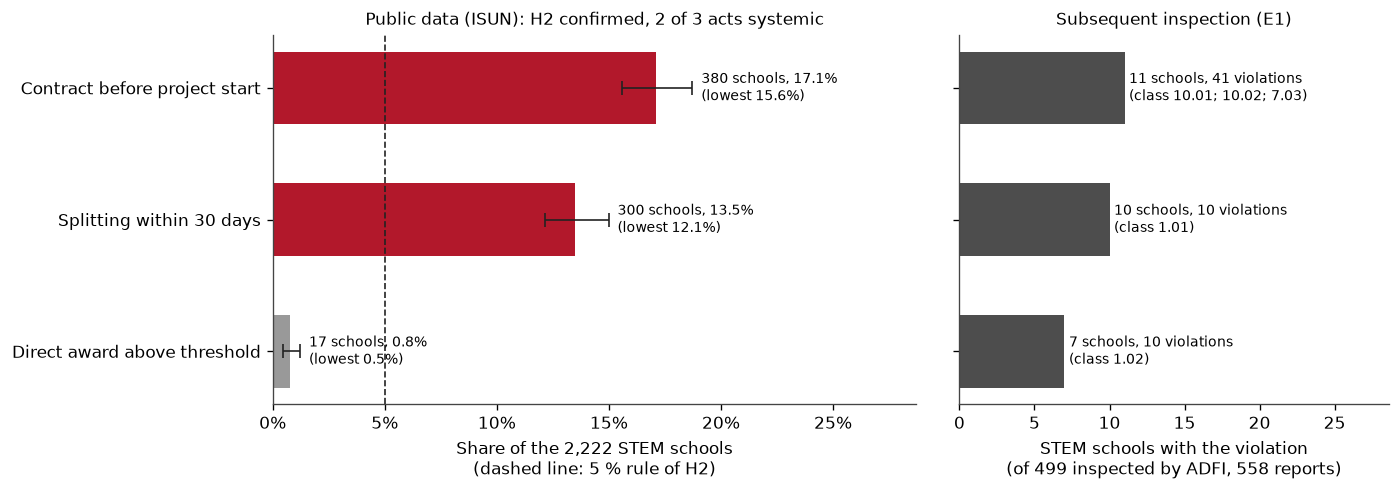

In [8]:
# Figure: for each act, STEM schools in the public data against the 5 % rule of H2, next to the STEM schools in which ADFI recorded it (E1).
fig_keys = list(ACT)
fig_lab = {
    "predated": "Contract before project start",
    "split_30d": "Splitting within 30 days",
    "regime_mismatch": "Direct award above threshold",
}
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.08}, sharey=True)
for i, k in enumerate(fig_keys):
    row = h2_view.loc[k]
    col = "#b2182b" if bool(row["ci95_lower_over_5pct"]) else "#999999"
    axL.barh(i, row["share_schools"], color=col, height=0.55)
    axL.errorbar(row["share_schools"], i,
                 xerr=[[row["share_schools"] - row["ci95_low"]], [row["ci95_high"] - row["share_schools"]]],
                 fmt="none", ecolor="#222222", capsize=4, lw=1)
    axL.text(row["ci95_high"] + 0.004, i,
             f"{int(row['n_schools'])} schools, {row['share_schools']:.1%}\n(lowest {row['ci95_low']:.1%})",
             va="center", fontsize=8.5)
    viol, e1_sch, _ = e1_text(k)
    axR.barh(i, e1_sch, color="#4d4d4d", height=0.55)
    axR.text(e1_sch + 0.3, i, f"{e1_sch} schools, {viol} violations\n(class {cmap.loc[k, 'e1_classes']})",
             va="center", fontsize=8.5)
axL.axvline(0.05, color="#222222", ls="--", lw=1)
axL.set_yticks(range(len(fig_keys)), [fig_lab[k] for k in fig_keys])
axL.invert_yaxis()
axL.xaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals=0))
axL.set_xlim(0, max(h2_view.loc[k, "ci95_high"] for k in fig_keys) + 0.10)
axL.set_xlabel(f"Share of the {N_SCHOOLS:,} STEM schools\n(dashed line: 5 % rule of H2)")
axL.set_title(f"Public data (ISUN): H2 {h2_decision}, {n_passing} of 3 acts systemic", fontsize=10)
axR.set_xlim(0, max(e1_text(k)[1] for k in fig_keys) * 2.6)
axR.set_xlabel(f"STEM schools with the violation\n(of {n_e1_schools} inspected by ADFI, {n_e1_reports} reports)")
axR.set_title("Subsequent inspection (E1)", fontsize=10)
for ax in (axL, axR):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.savefig(FIG_DIR / "F2_H2_systemic_failures.png", bbox_inches="tight")
plt.show()

## 5. Prices set just below the direct-award threshold (`bunching_50k`)

**What is done.** From 1 January 2024 a school may award a contract for goods or services directly, without a public call for offers, only if its value is below 50,000 BGN excl. VAT (Art. 20(4) PPA); at or above that value it must publish a call (Art. 20(3) PPA). This section counts the contracts signed from 2024 whose value lies just below the threshold, from 47,000 BGN up to the threshold, and compares them with the number that the values of the other contracts around the threshold would give if the threshold did not exist. The difference is the number of contracts whose price was brought below the threshold. The comparison is repeated in 14 ways fixed before the data were examined (other widths, other periods, other treatment of VAT and currency), so that the result does not depend on one choice. The exact prices that recur most often are listed as well.

**Why this is not part of H2.** Each of the three acts in Section 4.5 is seen in a single contract: its date or its value breaks a rule. A contract just below the threshold breaks no rule by itself. Only the excess over the expected number, across the whole programme, shows that prices were set to stay below the threshold. The result is therefore an indication for the financial controller, not a finding against a given contract.

**Why this matters for Element 1.** Before signature the financial controller checks that the estimated value of the contract rests on real market research (Art. 21(1)-(2) PPA) and that purchases from one supplier are not split (Art. 21(14)-(15) PPA). In its reports on the STEM schools ADFI checks the same points (classes 1.06 and 1.01). The public data show whether finding no violation there means that the prices were set by the market, or that an inspection of the file does not see a price brought just below the threshold.

**Figure F2_1.** It shows the contracts signed from 2024 around the 50,000 BGN threshold, with the expected number without the threshold, and the contracts signed up to 2023 around the 30,000 BGN threshold then in force. The thresholds for works (50,000 BGN up to 2023, 80,000 BGN from 2024) are drawn for reference only, because ISUN does not say whether a contract is for works.

In [9]:
reg2 = c_eval[c_eval["regime"] == 2].copy()
raw_arr = reg2["amount_raw"].to_numpy()
beur_arr = np.where(reg2["currency"] == "BGN", raw_arr / EUR_BGN, raw_arr)
vb_excl_alt = np.where(reg2["vat_basis"] == "undetermined", "excl_vat", reg2["vat_basis"])
reg2["bgn_excl_if_no_vat"] = np.round(np.where(vb_excl_alt == "incl_vat", beur_arr / VAT_FACTOR, beur_arr) * EUR_BGN, 2)


def fit_poisson_bunching(values, threshold=50000.0, bin_width=1000.0, half_window=15000.0, band_below=3000.0, band_above=3000.0, degree=3):
    """Fit Poisson QML counterfactual polynomial with HC1 standard errors."""
    n_bins = int(round(2.0 * half_window / bin_width))
    edges = threshold - half_window + bin_width * np.arange(n_bins + 1)
    counts, _ = np.histogram(np.asarray(values, dtype=float), bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2.0
    dist = (centers - threshold) / 10000.0
    below = (centers >= threshold - band_below) & (centers < threshold)
    above = (centers >= threshold) & (centers < threshold + band_above)
    X = np.column_stack([dist ** p for p in range(degree + 1)] + [below.astype(float), above.astype(float)])
    model = Poisson(counts, X).fit(disp=0, maxiter=200, cov_type="HC1")
    cf = np.exp(X[:, : degree + 1] @ model.params[: degree + 1])
    b1 = float(model.params[degree + 1])
    se1 = float(model.bse[degree + 1])
    p1 = float(model.pvalues[degree + 1])
    obs_b = int(counts[below].sum())
    exp_b = float(cf[below].sum())
    exc_b = float(np.sum(counts[below] - cf[below]))
    pct_exc = float((np.exp(b1) - 1.0) * 100.0)
    return {
        "edges": edges,
        "centers": centers,
        "counts": counts,
        "counterfactual": cf,
        "below": below,
        "above": above,
        "observed": obs_b,
        "expected": exp_b,
        "excess": exc_b,
        "percent_excess": pct_exc,
        "beta_1": b1,
        "se_1": se1,
        "p_value": p1,
        "converged": bool(model.mle_retvals["converged"]),
    }


pos_reg2 = reg2["amount_bgn_excl_vat"] > 0.0
yr_reg2 = pd.to_datetime(reg2["signature_date"]).dt.year
specs = [
    ("1. Baseline (deg=3, bin=1k, hw=15k, band=3k)", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {}),
    ("2. Undetermined VAT assumed excl. VAT", reg2.loc[reg2["bgn_excl_if_no_vat"] > 0, "bgn_excl_if_no_vat"].to_numpy(), {}),
    ("3. Known VAT basis only", reg2.loc[pos_reg2 & (reg2["vat_basis"] != "undetermined"), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("4. Known currency (excl. default) only", reg2.loc[pos_reg2 & (reg2["currency_basis"] != "default"), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("5. Signed in 2024 only", reg2.loc[pos_reg2 & (yr_reg2 == 2024), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("6. Signed from 2025 onward", reg2.loc[pos_reg2 & (yr_reg2 >= 2025), "amount_bgn_excl_vat"].to_numpy(), {}),
    ("7. Bin width 500 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"bin_width": 500.0}),
    ("8. Bin width 2,000 BGN, bands 4,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"bin_width": 2000.0, "half_window": 16000.0, "band_below": 4000.0, "band_above": 4000.0}),
    ("9. Polynomial degree 2", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"degree": 2}),
    ("10. Polynomial degree 4", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"degree": 4}),
    ("11. Half-window 10,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"half_window": 10000.0}),
    ("12. Half-window 20,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"half_window": 20000.0}),
    ("13. Bands 2,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"band_below": 2000.0, "band_above": 2000.0}),
    ("14. Bands 4,000 BGN", reg2.loc[pos_reg2, "amount_bgn_excl_vat"].to_numpy(), {"band_below": 4000.0, "band_above": 4000.0}),
]

spec_rows = []
base_fit = None
for idx_s, (lbl, vv, kw) in enumerate(specs):
    res = fit_poisson_bunching(vv, **kw)
    assert res["converged"], f"Non-convergence in {lbl}"
    if idx_s == 0:
        base_fit = res
    spec_rows.append({
        "specification": lbl,
        "observed": res["observed"],
        "expected": res["expected"],
        "excess": res["excess"],
        "percent_excess": res["percent_excess"],
        "p_value": res["p_value"],
    })
specs_df = pd.DataFrame(spec_rows)
specs_df["q_bh"] = bh_fdr(specs_df["p_value"].to_numpy())
display(specs_df.style.hide(axis="index").format({"expected": "{:.1f}", "excess": "{:+.1f}", "percent_excess": "{:+.1f}%", "p_value": "{:.4f}", "q_bh": "{:.4f}"}))

b50_mask = (c_eval["regime"] == 2) & (c_eval["amount_bgn_excl_vat"] >= 47000.0) & (c_eval["amount_bgn_excl_vat"] < 50000.0)
b50_max = float(c_eval.loc[(c_eval["regime"] == 2) & (c_eval["amount_bgn_excl_vat"] < 50000.0), "amount_bgn_excl_vat"].max())
b50_row = summarize_indicator(b50_mask, "bunching_50k", "Price bunching in [47,000; 49,999.91] BGN excl. VAT", False, "", f"Poisson QML: obs={base_fit['observed']}, exp={base_fit['expected']:.1f}, excess={base_fit['percent_excess']:+.1f}%, p={base_fit['p_value']:.4f}, q={specs_df.loc[0, 'q_bh']:.4f} -> indication")
t21_df = pd.concat([t21_df, pd.DataFrame([b50_row])], ignore_index=True)
t21_df.to_csv(DERIVED_DIR / "T2_1_indicators.csv", index=False, encoding="utf-8", lineterminator="\n")

focal_bgn = reg2[pos_reg2].groupby("amount_bgn_excl_vat").agg(contracts=("contract_row", "count"), schools=("school_bulstat", "nunique")).sort_values("contracts", ascending=False).head(8).reset_index()
focal_raw = c_eval[c_eval["amount_raw"] > 0].groupby("amount_raw").agg(contracts=("contract_row", "count"), schools=("school_bulstat", "nunique")).sort_values("contracts", ascending=False).head(8).reset_index()
display(focal_bgn.style.hide(axis="index").format({"amount_bgn_excl_vat": "{:,.2f}"}))
display(focal_raw.style.hide(axis="index").format({"amount_raw": "{:,.2f}"}))

record_conclusion("Section 5", "bunching_50k", "bunching_50k: observed contracts in [47k, 50k)", base_fit["observed"])
record_conclusion("Section 5", "bunching_50k", "bunching_50k: max contract value below 50k BGN", f"{b50_max:.2f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: counterfactual expected contracts", f"{base_fit['expected']:.1f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: excess contracts", f"{base_fit['excess']:.1f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: percent excess", f"{base_fit['percent_excess']:.2f}")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: Poisson QML p-value", f"{base_fit['p_value']:.4f}", "", "", "HC1", "indication")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: BH-FDR q-value across 14 specs", f"{specs_df.loc[0, 'q_bh']:.4f}", "", "", "BH-FDR", "indication")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: specs significant at p<=0.05 (of 14)", int((specs_df["p_value"] <= 0.05).sum()))
record_conclusion("Section 5", "bunching_50k", "bunching_50k: schools", b50_row["n_schools"])
record_conclusion("Section 5", "bunching_50k", "bunching_50k: share of schools", f"{b50_row['share_schools']:.6f}", f"{b50_row['ci95_low']:.6f}", f"{b50_row['ci95_high']:.6f}", "Wilson", "indication")
record_conclusion("Section 5", "bunching_50k", "bunching_50k: value EUR incl VAT", f"{b50_row['value_eur_incl_vat']:.2f}")
flush_conclusions()


specification,observed,expected,excess,percent_excess,p_value,q_bh
"1. Baseline (deg=3, bin=1k, hw=15k, band=3k)",295,184.1,+110.9,+60.2%,0.0341,0.0615
2. Undetermined VAT assumed excl. VAT,280,202.2,+77.8,+38.5%,0.1332,0.1554
3. Known VAT basis only,168,93.2,+74.8,+80.2%,0.0439,0.0615
4. Known currency (excl. default) only,224,140.1,+83.9,+59.9%,0.0978,0.1245
5. Signed in 2024 only,104,54.9,+49.1,+89.5%,0.0420,0.0615
6. Signed from 2025 onward,191,127.9,+63.1,+49.3%,0.0269,0.0615
7. Bin width 500 BGN,295,184.7,+110.3,+59.7%,0.0304,0.0615
"8. Bin width 2,000 BGN, bands 4,000 BGN",356,264.7,+91.3,+34.5%,0.2678,0.2678
9. Polynomial degree 2,295,185.6,+109.4,+58.9%,0.0364,0.0615
10. Polynomial degree 4,295,172.2,+122.8,+71.3%,0.0161,0.0563


amount_bgn_excl_vat,contracts,schools
"24,999.00",91,91
"8,332.99",42,42
"12,500.00",39,39
"24,999.01",34,34
"3,000.00",31,30
"2,083.33",25,25
"41,665.00",25,25
"1,500.01",22,22


amount_raw,contracts,schools
"29,998.80",59,59
"15,338.14",51,51
"5,112.71",44,44
"15,338.15",35,35
"7,669.38",29,29
920.33,23,23
"1,278.23",20,20
"1,840.65",19,18


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
86,Section 5,bunching_50k,bunching_50k: BH-FDR q-value across 14 specs,0.0615,,,BH-FDR,indication
87,Section 5,bunching_50k,bunching_50k: specs significant at p<=0.05 (of...,10,,,none,none
88,Section 5,bunching_50k,bunching_50k: schools,274,,,none,none
89,Section 5,bunching_50k,bunching_50k: share of schools,0.123312,0.110288,0.137637,Wilson,indication


In [10]:
# Economic conclusions of Section 5: every figure is taken from this run; the E1 classes come from concepts_df (Section 3).
b50 = t21_df.set_index("indicator").loc["bunching_50k"]
n_r2 = int(len(reg2))
n_specs = int(len(specs_df))
n_specs_pos = int((specs_df["excess"] > 0).sum())
n_specs_sig = int((specs_df["p_value"] <= 0.05).sum())
b50_proven = bool(specs_df.loc[0, "q_bh"] <= 0.05)
e106 = e1_stem[e1_stem["class_index"] == "1.06"]
e106_viol = int(e106["is_violation"].sum())
e101 = e1_stem[(e1_stem["class_index"] == "1.01") & e1_stem["is_violation"]]
assert cmap.loc["bunching_50k", "e1_classes"] == "1.01; 1.06"

lines = [
    f"Of the {n_r2:,} contracts signed from 2024, {base_fit['observed']} have a value just below the threshold for direct award "
    f"(from 47,000 to {b50_max:,.2f} BGN excl. VAT), while the values of the other contracts around the threshold would give "
    f"about {base_fit['expected']:.0f}: {base_fit['excess']:.0f} contracts more ({base_fit['percent_excess']:+.0f} %). "
    f"These contracts were signed by {int(b50['n_schools']):,} schools ({b50['share_schools']:.1%}) and are worth "
    f"EUR {b50['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT; EUR {b50['paid_eur_incl_vat'] / 1e6:,.2f} m of it has already been paid "
    f"and EUR {b50['unpaid_eur_incl_vat'] / 1e6:,.2f} m is not yet paid. "
    f"It means that schools and suppliers set the price so that the contract stays in direct award, without a public call for offers.",
    (f"The excess appears in all {n_specs} ways of measuring it" if n_specs_pos == n_specs
     else f"The excess appears in {n_specs_pos} of the {n_specs} ways of measuring it")
    + f" and is clear in {n_specs_sig} of them; "
    + ("taken together, it is established. " if b50_proven else "taken together, it is not strong enough to count as proof. ")
    + "It means that a price just below the threshold is a signal for the financial controller to check the market research "
    "behind it, not proof of a violation in a given contract.",
    "The most frequent prices are exact amounts repeated at many schools: "
    + ", ".join(f"{r.amount_bgn_excl_vat:,.2f} BGN excl. VAT in {r.contracts} contracts at {r.schools} schools"
                for r in focal_bgn.head(3).itertuples())
    + ". It means that these prices were not set by each school's own market research.",
    f"In its reports on the {n_e1_schools} STEM schools it inspected, ADFI checked how the estimated value was set "
    f"{len(e106)} times in {e106['rk'].nunique()} reports and found "
    + (f"no violation" if e106_viol == 0 else f"{e106_viol} violations")
    + f"; it recorded splitting of purchases as a violation {len(e101)} times, in {e101['school_bulstat'].nunique()} schools. "
    f"It means that the inspection finds in the file an estimate below the threshold and sees nothing wrong, while across "
    f"the programme {base_fit['excess']:.0f} more contracts than expected sit just below it. Only ex-ante control before signature, "
    f"checking whether the market research is real and whether the school has other contracts with the same supplier, can stop it.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. Of the 11,055 contracts signed from 2024, 295 have a value just below the threshold for direct award (from 47,000 to 49,999.91 BGN excl. VAT), while the values of the other contracts around the threshold would give about 184: 111 contracts more (+60 %). These contracts were signed by 274 schools (12.3%) and are worth EUR 8.84 m incl. VAT; EUR 8.37 m of it has already been paid and EUR 0.48 m is not yet paid. It means that schools and suppliers set the price so that the contract stays in direct award, without a public call for offers.

2. The excess appears in all 14 ways of measuring it and is clear in 10 of them; taken together, it is not strong enough to count as proof. It means that a price just below the threshold is a signal for the financial controller to check the market research behind it, not proof of a violation in a given contract.

3. The most frequent prices are exact amounts repeated at many schools: 24,999.00 BGN excl. VAT in 91 contracts at 91 schools, 8,332.99 BGN e

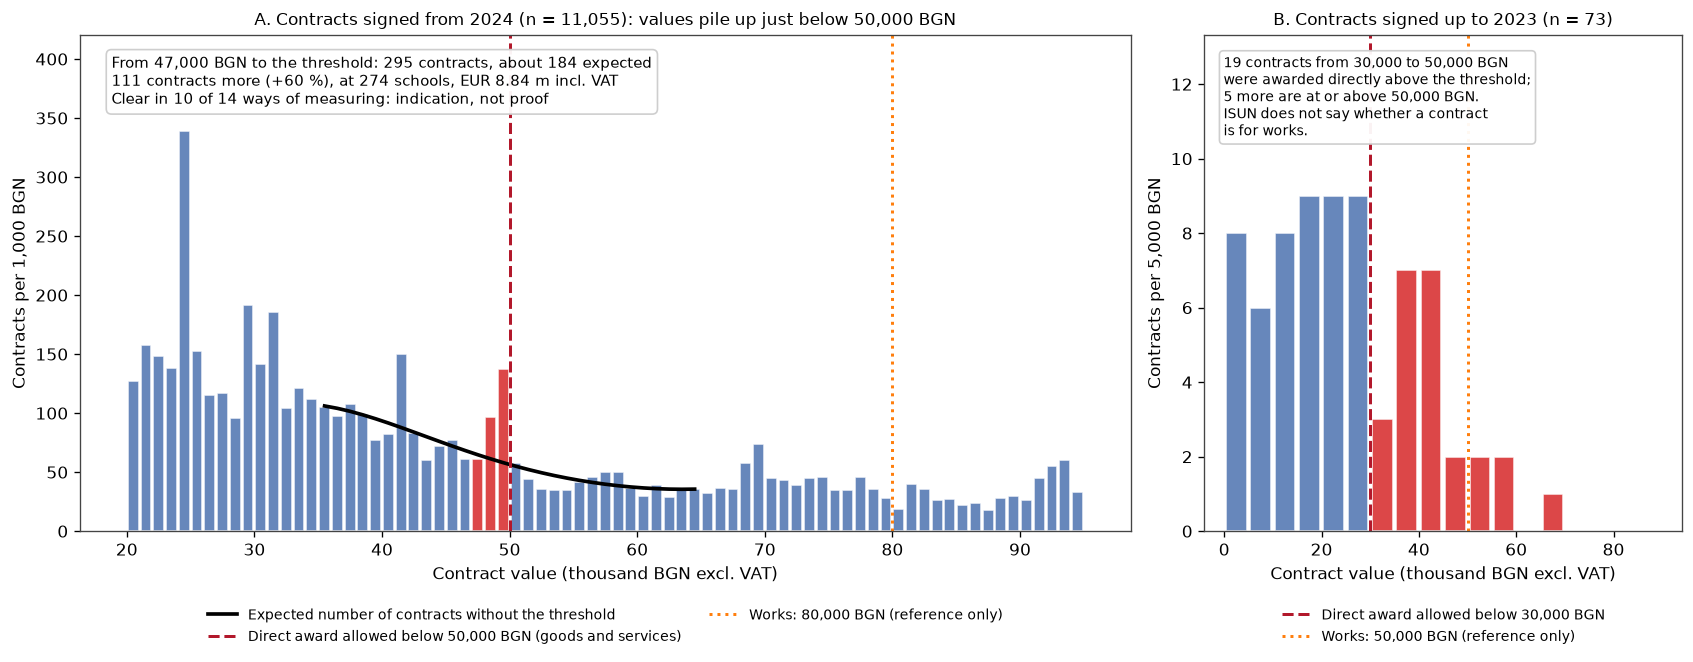

In [11]:
# Figure F2_1: contract values around the direct-award thresholds; every number in the figure is taken from this run.
reg1 = c_eval[c_eval["regime"] == 1]
n_r1 = int(len(reg1))
r1_30_50 = int(((reg1["amount_bgn_excl_vat"] >= 30000.0) & (reg1["amount_bgn_excl_vat"] < 50000.0)).sum())
r1_50 = int((reg1["amount_bgn_excl_vat"] >= 50000.0).sum())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [2.2, 1.0]}, constrained_layout=True)
bin_edges_r2 = np.arange(20000.0, 96000.0, 1000.0)
cnts_r2, _ = np.histogram(reg2.loc[pos_reg2, "amount_bgn_excl_vat"], bins=bin_edges_r2)
ctrs_r2 = (bin_edges_r2[:-1] + bin_edges_r2[1:]) / 2.0
bar_colors = ["#d62728" if (47000.0 <= c < 50000.0) else "#4c72b0" for c in ctrs_r2]
ax1.bar(ctrs_r2 / 1000.0, cnts_r2, width=0.85, color=bar_colors, alpha=0.85, edgecolor="white")
ax1.plot(base_fit["centers"] / 1000.0, base_fit["counterfactual"], color="black", linewidth=2.2,
         label="Expected number of contracts without the threshold")
ax1.axvline(50.0, color="#b2182b", linestyle="--", linewidth=1.8, label="Direct award allowed below 50,000 BGN (goods and services)")
ax1.axvline(80.0, color="#ff7f0e", linestyle=":", linewidth=1.8, label="Works: 80,000 BGN (reference only)")
ax1.set_xlabel("Contract value (thousand BGN excl. VAT)")
ax1.set_ylabel("Contracts per 1,000 BGN")
ax1.set_title(f"A. Contracts signed from 2024 (n = {n_r2:,}): values pile up just below 50,000 BGN", fontsize=10)
ax1.set_ylim(0, float(cnts_r2.max()) * 1.24)
ax1.text(0.03, 0.96,
         f"From 47,000 BGN to the threshold: {base_fit['observed']} contracts, about {base_fit['expected']:.0f} expected\n"
         f"{base_fit['excess']:.0f} contracts more ({base_fit['percent_excess']:+.0f} %), at {int(b50['n_schools']):,} schools, "
         f"EUR {b50['value_eur_incl_vat'] / 1e6:,.2f} m incl. VAT\n"
         f"Clear in {n_specs_sig} of {n_specs} ways of measuring: {'established' if b50_proven else 'indication, not proof'}",
         transform=ax1.transAxes, va="top", fontsize=9, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#cccccc", alpha=0.95))
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.5, frameon=False)

edges_r1 = np.arange(0.0, 95000.0, 5000.0)
cnts_r1, _ = np.histogram(reg1["amount_bgn_excl_vat"], bins=edges_r1)
ctrs_r1 = (edges_r1[:-1] + edges_r1[1:]) / 2.0
cols_r1 = ["#d62728" if c >= 30000.0 else "#4c72b0" for c in ctrs_r1]
ax2.bar(ctrs_r1 / 1000.0, cnts_r1, width=4.2, color=cols_r1, alpha=0.85, edgecolor="white")
ax2.axvline(30.0, color="#b2182b", linestyle="--", linewidth=1.8, label="Direct award allowed below 30,000 BGN")
ax2.axvline(50.0, color="#ff7f0e", linestyle=":", linewidth=1.8, label="Works: 50,000 BGN (reference only)")
ax2.set_xlabel("Contract value (thousand BGN excl. VAT)")
ax2.set_ylabel("Contracts per 5,000 BGN")
ax2.set_title(f"B. Contracts signed up to 2023 (n = {n_r1})", fontsize=10)
ax2.set_ylim(0, max(float(cnts_r1.max()) * 1.48, 12.5))
ax2.text(0.04, 0.96,
         f"{r1_30_50} contracts from 30,000 to 50,000 BGN\nwere awarded directly above the threshold;\n"
         f"{r1_50} more are at or above 50,000 BGN.\nISUN does not say whether a contract\nis for works.",
         transform=ax2.transAxes, va="top", fontsize=8.2, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc", alpha=0.95))
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=1, fontsize=8.5, frameon=False)

fig.savefig(FIG_DIR / "F2_1_values_around_thresholds.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Where the acts occur: 28 regions and the profile of Blagoevgrad

**What is done.** For each of the 28 regions (by the regional education office of the school) this section counts the STEM schools with at least one of the three acts of Section 4.5: signing the contract before the project started, splitting purchases from one supplier within 30 days, and awarding a contract directly although its value required a call or a procedure. Each share comes with the range within which it could lie by chance, which is wide in regions with few schools. The acts are also shown one by one, together with the prices just below the direct-award threshold from Section 5, and for each region the supplier with the largest part of the contracted value is named. One test checks whether the regions differ more than chance would allow. Blagoevgrad is then examined municipality by municipality, with the largest supplier's part of the contracted value, and with the ADFI reports on its STEM schools from Element 1.

**Why this matters for Element 1.** If the acts were spread evenly across the country, ADFI and the managing authority could choose the schools to inspect at random. If they are concentrated in some regions, the public data give a map of where control before signature and inspection after it should go first. The ADFI reports on the STEM schools of Blagoevgrad show whether the inspected schools are the ones where the public data find the acts.

**Figure F2_2.** Panel A shows for each region the share of its STEM schools with at least one of the three acts, the range that chance could give, and the share for all regions together; Blagoevgrad is marked. Panel B shows the share for each act separately and for prices just below the threshold. Direct award above the threshold is not drawn separately because it concerns very few schools.

In [12]:
c_eval["flag_level1"] = l1_mask.to_numpy()
c_eval["flag_bunching_50k"] = b50_mask.to_numpy()

sch_base = schools.drop_duplicates("school_bulstat").set_index("school_bulstat")
sch_reg = c_eval.groupby("school_bulstat").agg(
    contracts=("contract_row", "count"),
    contracted_eur_incl_vat=("amount_eur_incl_vat", "sum"),
    contracted_eur_excl_vat=("amount_eur_excl_vat", "sum"),
    paid_eur_incl_vat=("paid_alloc_eur_incl_vat", "sum"),
    flag_predated=("flag_predated", "any"),
    flag_split_30d=("flag_split_30d", "any"),
    flag_regime_mismatch=("flag_regime_mismatch", "any"),
    flag_level1=("flag_level1", "any"),
    flag_bunching_50k=("flag_bunching_50k", "any"),
    l1_contracts=("flag_level1", "sum"),
)
for col in ("school_name", "oblast_ruo", "municipality", "funding_type", "detailed_type", "register_budget_bgn_incl_vat"):
    sch_reg[col] = sch_base[col]
sch_reg["l1_val_incl_vat"] = (
    c_eval.loc[c_eval["flag_level1"]].groupby("school_bulstat")["amount_eur_incl_vat"].sum()
    .reindex(sch_reg.index, fill_value=0.0)
)
sch_reg = sch_reg.reset_index()

c_by_ob_ven = (
    c_eval.groupby(["oblast_ruo", "vendor_id", "vendor_eik", "vendor_name"], as_index=False)["amount_eur_incl_vat"]
    .sum()
    .sort_values(["oblast_ruo", "amount_eur_incl_vat"], ascending=[True, False])
)
ob_top_ven = c_by_ob_ven.drop_duplicates("oblast_ruo").set_index("oblast_ruo")

ob_rows = []
for ob, g in sch_reg.groupby("oblast_ruo"):
    n_s = int(len(g))
    k_l1 = int(g["flag_level1"].sum())
    p_l1, lo_l1, hi_l1 = wilson_ci(k_l1, n_s)
    k_pr = int(g["flag_predated"].sum())
    k_sp = int(g["flag_split_30d"].sum())
    k_rm = int(g["flag_regime_mismatch"].sum())
    k_b5 = int(g["flag_bunching_50k"].sum())
    tot_v = float(g["contracted_eur_incl_vat"].sum())
    top_r = ob_top_ven.loc[ob]
    ob_rows.append({
        "oblast": ob,
        "schools": n_s,
        "contracts": int(g["contracts"].sum()),
        "contracted_eur_incl_vat": round(tot_v, 2),
        "paid_eur_incl_vat": round(float(g["paid_eur_incl_vat"].sum()), 2),
        "predated_schools": k_pr,
        "predated_pct": round(k_pr / n_s * 100.0, 2),
        "split_30d_schools": k_sp,
        "split_30d_pct": round(k_sp / n_s * 100.0, 2),
        "regime_mismatch_schools": k_rm,
        "level1_schools": k_l1,
        "level1_pct": round(p_l1 * 100.0, 2),
        "level1_ci_low": round(lo_l1 * 100.0, 2),
        "level1_ci_high": round(hi_l1 * 100.0, 2),
        "level1_contracts": int(g["l1_contracts"].sum()),
        "level1_val_incl_vat": round(float(g["l1_val_incl_vat"].sum()), 2),
        "bunching_50k_schools": k_b5,
        "bunching_50k_pct": round(k_b5 / n_s * 100.0, 2),
        "top_supplier": str(top_r["vendor_name"]),
        "top_supplier_eik": str(top_r["vendor_eik"]),
        "oblast_c1_pct": round(float(top_r["amount_eur_incl_vat"]) / tot_v * 100.0, 2) if tot_v > 0 else 0.0,
    })

ob_df = pd.DataFrame(ob_rows).sort_values(["level1_pct", "schools", "oblast"], ascending=[False, False, True]).reset_index(drop=True)
ob_df["rank_l1"] = np.arange(1, len(ob_df) + 1)

chi2_ob, p_chi2_ob, dof_ob, _ = stats.chi2_contingency(
    np.column_stack([ob_df["level1_schools"].to_numpy(), (ob_df["schools"] - ob_df["level1_schools"]).to_numpy()])
)
print(f"Regional heterogeneity across 28 oblasts: chi2 = {chi2_ob:.2f} (df={dof_ob}, p={p_chi2_ob:.3e})")
display(ob_df[[
    "rank_l1", "oblast", "schools", "contracts", "level1_schools", "level1_pct",
    "level1_ci_low", "level1_ci_high", "predated_pct", "split_30d_pct",
    "bunching_50k_pct", "oblast_c1_pct", "top_supplier"
]])

top_ob = ob_df.iloc[0]
bot_ob = ob_df.iloc[-1]
blg_ob = ob_df[ob_df["oblast"] == "Благоевград"].iloc[0]
record_conclusion("Section 6", "regional", "regional heterogeneity p-value (chi2 across 28 oblasts)", f"{p_chi2_ob:.8f}", "", "", "chi2", "heterogeneous")
record_conclusion("Section 6", "regional", "highest Level 1 oblast name", str(top_ob["oblast"]))
record_conclusion("Section 6", "regional", "highest Level 1 oblast share (%)", f"{top_ob['level1_pct']:.2f}", f"{top_ob['level1_ci_low']:.2f}", f"{top_ob['level1_ci_high']:.2f}", "Wilson 95%", str(top_ob["oblast"]))
record_conclusion("Section 6", "regional", "lowest Level 1 oblast name", str(bot_ob["oblast"]))
record_conclusion("Section 6", "regional", "lowest Level 1 oblast share (%)", f"{bot_ob['level1_pct']:.2f}", f"{bot_ob['level1_ci_low']:.2f}", f"{bot_ob['level1_ci_high']:.2f}", "Wilson 95%", str(bot_ob["oblast"]))
record_conclusion("Section 6", "regional", "Blagoevgrad rank (of 28)", int(blg_ob["rank_l1"]))
record_conclusion("Section 6", "regional", "Blagoevgrad schools count", int(blg_ob["schools"]))
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 schools count", int(blg_ob["level1_schools"]))
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 schools (%)", f"{blg_ob['level1_pct']:.2f}", f"{blg_ob['level1_ci_low']:.2f}", f"{blg_ob['level1_ci_high']:.2f}", "Wilson 95%", f"{int(blg_ob['level1_schools'])}/{int(blg_ob['schools'])}")
record_conclusion("Section 6", "regional", "Blagoevgrad total contracts count", int(blg_ob["contracts"]))
record_conclusion("Section 6", "regional", "Blagoevgrad total contracted EUR incl VAT", f"{blg_ob['contracted_eur_incl_vat']:.2f}")
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 contracts count", int(blg_ob["level1_contracts"]))
record_conclusion("Section 6", "regional", "Blagoevgrad Level 1 contracted EUR incl VAT", f"{blg_ob['level1_val_incl_vat']:.2f}")

blg_c = c_eval[c_eval["oblast_ruo"] == "Благоевград"].copy()
blg_s = sch_reg[sch_reg["oblast_ruo"] == "Благоевград"].copy()
blg_muni_rows = []
for mun, mg in blg_c.groupby("municipality"):
    ms = blg_s[blg_s["municipality"] == mun]
    by_v = mg.groupby(["vendor_eik", "vendor_name"], as_index=False)["amount_eur_incl_vat"].sum().sort_values("amount_eur_incl_vat", ascending=False)
    tot_m = float(mg["amount_eur_incl_vat"].sum())
    blg_muni_rows.append({
        "municipality": mun,
        "schools": int(len(ms)),
        "contracts": int(len(mg)),
        "contracted_eur_incl_vat": round(tot_m, 2),
        "level1_schools": int(ms["flag_level1"].sum()),
        "level1_pct": round(float(ms["flag_level1"].mean()) * 100.0, 1),
        "c1_pct": round(float(by_v.iloc[0]["amount_eur_incl_vat"]) / tot_m * 100.0, 2) if tot_m > 0 else 0.0,
        "top_supplier": str(by_v.iloc[0]["vendor_name"]),
        "top_supplier_eik": str(by_v.iloc[0]["vendor_eik"]),
    })
blg_muni_df = pd.DataFrame(blg_muni_rows).sort_values(["c1_pct", "schools"], ascending=[False, False]).reset_index(drop=True)
print(f"\nBlagoevgrad deep dive: rank {int(blg_ob['rank_l1'])}/28, {int(blg_ob['level1_schools'])}/{int(blg_ob['schools'])} schools ({blg_ob['level1_pct']:.2f}%), {int(blg_ob['contracts'])} contracts ({blg_ob['contracted_eur_incl_vat']:,.2f} EUR incl. VAT), Level 1: {int(blg_ob['level1_contracts'])} contracts ({blg_ob['level1_val_incl_vat']:,.2f} EUR incl. VAT).")
display(blg_muni_df)

for fm_mun in ("Белица", "Банско", "Благоевград"):
    r_m = blg_muni_df[blg_muni_df["municipality"] == fm_mun].iloc[0]
    record_conclusion("Section 6", "regional", f"Blagoevgrad {fm_mun} C1 supplier share (%)", f"{r_m['c1_pct']:.2f}", "", "", "top_supplier", str(r_m["top_supplier"]))

norm_map = dict(zip(project_classes["school_bulstat_isun"], project_classes["school_bulstat"]))
stem_set = set(sch_reg["school_bulstat"])
adfi_m_tmp = adfi_meta.copy()
adfi_m_tmp["stem_b"] = adfi_m_tmp["eik"].map(lambda e: e if e in stem_set else norm_map.get(e, ""))
blg_aud_meta = adfi_m_tmp[adfi_m_tmp["stem_b"].isin(set(blg_s["school_bulstat"]))].copy()
blg_aud_sch = set(blg_aud_meta["stem_b"])
blg_aud_l1 = blg_aud_sch & set(blg_s.loc[blg_s["flag_level1"], "school_bulstat"])
print(f"ADFI audits in Blagoevgrad: {len(blg_aud_meta)} reports across {len(blg_aud_sch)} STEM schools (directorates: {blg_aud_meta['directorate_bg'].value_counts().to_dict()}); {len(blg_aud_l1)} audited schools have Level 1 indicators.")
record_conclusion("Section 6", "regional", "Blagoevgrad ADFI audited schools", int(len(blg_aud_sch)))
record_conclusion("Section 6", "regional", "Blagoevgrad ADFI reports count", int(len(blg_aud_meta)))
record_conclusion("Section 6", "regional", "Blagoevgrad ADFI audited with Level 1", int(len(blg_aud_l1)))
flush_conclusions()

Regional heterogeneity across 28 oblasts: chi2 = 77.40 (df=27, p=9.304e-07)


,rank_l1,oblast,schools,contracts,level1_schools,level1_pct,level1_ci_low,level1_ci_high,predated_pct,split_30d_pct,bunching_50k_pct,oblast_c1_pct,top_supplier
0,1,Перник,41,166,23,56.10,41.04,70.11,46.34,9.76,7.32,32.54,БАЛИСТИК СЕЛ ЕООД
1,2,Монтана,59,244,27,45.76,33.70,58.34,40.68,6.78,10.17,16.42,Офис 1 Запад ЕООД
2,3,Търговище,48,284,21,43.75,30.70,57.72,16.67,29.17,12.50,11.76,",,А1 България“ ЕАД"
3,4,Русе,64,412,26,40.62,29.46,52.85,29.69,12.50,17.19,10.05,СИЕНСИС АД
4,5,Силистра,41,198,16,39.02,25.66,54.27,31.71,9.76,7.32,14.56,",,А1 България“ ЕАД"
5,6,Велико Търново,81,421,30,37.04,27.33,47.92,24.69,13.58,11.11,15.67,ВАЛИ КОМПЮТЪРС ООД
6,7,София-област,92,458,34,36.96,27.80,47.16,18.48,20.65,14.13,13.38,Кооперация Панда
7,8,Благоевград,120,535,43,35.83,27.82,44.73,16.67,22.50,14.17,16.13,Уеб Сървисис ЕООД
8,9,Видин,32,123,11,34.38,20.41,51.69,18.75,15.62,3.12,21.33,Кооперация Панда
9,10,Хасково,79,420,26,32.91,23.55,43.85,21.52,13.92,16.46,20.83,Кооперация Панда



Blagoevgrad deep dive: rank 8/28, 43/120 schools (35.83%), 535 contracts (15,205,734.22 EUR incl. VAT), Level 1: 108 contracts (1,634,844.80 EUR incl. VAT).


,municipality,schools,contracts,contracted_eur_incl_vat,level1_schools,level1_pct,c1_pct,top_supplier,top_supplier_eik
0,Кресна,1,5,124935.98,0,0.0,69.36,Уеб Сървисис ЕООД,200544954
1,Гърмен,8,44,1258429.22,2,25.0,63.41,ГАРАНТ-2004 ЕООД,101661176
2,Якоруда,6,20,465227.30,1,16.7,54.24,Кооперация Панда,000885099
3,Струмяни,1,5,122693.15,0,0.0,49.99,ЦЕНТЪР ЗА ТВОРЧЕСКО ОБУЧЕНИЕ ООД,175342714
4,Сандански,11,40,1278347.24,3,27.3,46.47,Уеб Сървисис ЕООД,200544954
5,Сатовча,13,53,832451.95,8,61.5,43.40,",,А1 България“ ЕАД",131468980
6,Гоце Делчев,14,63,1818003.36,8,57.1,37.39,Юнион Интерактив ООД,204660454
7,Белица,6,28,739408.02,2,33.3,34.42,Кооперация Панда,000885099
8,Симитли,3,14,377275.67,1,33.3,33.70,",,А1 България“ ЕАД",131468980
9,Хаджидимово,5,17,483804.64,1,20.0,30.22,Юнион Интерактив ООД,204660454


ADFI audits in Blagoevgrad: 22 reports across 20 STEM schools (directorates: {'ДИД4': 22}); 8 audited schools have Level 1 indicators.


,part,question,measure,value,interval_low,interval_high,interval_method,decision
0,Section 2,reconciliation,projects in BG-RRP-1.015,2228,,,none,none
1,Section 2,reconciliation,unique beneficiary schools,2227,,,none,none
2,Section 2,reconciliation,projects with contract,2223,,,none,none
3,Section 2,reconciliation,schools with contract,2222,,,none,none
4,Section 2,reconciliation,projects without contract,5,,,none,none
...,...,...,...,...,...,...,...,...
105,Section 6,regional,Blagoevgrad Банско C1 supplier share (%),22.99,,,top_supplier,СТЕМО ЕООД
106,Section 6,regional,Blagoevgrad Благоевград C1 supplier share (%),26.97,,,top_supplier,АЙ ОФИС ООД
107,Section 6,regional,Blagoevgrad ADFI audited schools,20,,,none,none
108,Section 6,regional,Blagoevgrad ADFI reports count,22,,,none,none


In [13]:
# Economic conclusions of Section 6: every figure is taken from this run; the E1 classes come from concepts_df (Section 3) and the STEM-only E1 rows (e1_stem) from Section 3.
OBLAST_EN = {
    "Благоевград": "Blagoevgrad", "Бургас": "Burgas", "Варна": "Varna",
    "Велико Търново": "Veliko Tarnovo", "Видин": "Vidin", "Враца": "Vratsa",
    "Габрово": "Gabrovo", "Добрич": "Dobrich", "Кърджали": "Kardzhali",
    "Кюстендил": "Kyustendil", "Ловеч": "Lovech", "Монтана": "Montana",
    "Пазарджик": "Pazardzhik", "Перник": "Pernik", "Плевен": "Pleven",
    "Пловдив": "Plovdiv", "Разград": "Razgrad", "Русе": "Ruse",
    "Силистра": "Silistra", "Сливен": "Sliven", "Смолян": "Smolyan",
    "София-град": "Sofia-City", "София-област": "Sofia Oblast", "Софийска област": "Sofia Oblast",
    "Стара Загора": "Stara Zagora", "Търговище": "Targovishte",
    "Хасково": "Haskovo", "Шумен": "Shumen", "Ямбол": "Yambol",
}
ACT_SHORT = {
    "predated_pct": "contracts signed before the project started",
    "split_30d_pct": "purchases from one supplier split within 30 days",
}
nat_share = float(sch_reg["flag_level1"].mean())
p_text = "less than 1 in 1,000" if p_chi2_ob < 0.001 else f"{p_chi2_ob:.3f}"
top3 = ob_df.head(3)
blg_lead = max(ACT_SHORT, key=lambda c: blg_ob[c])
c1_munis = blg_muni_df[(blg_muni_df["c1_pct"] > 50.0) & (blg_muni_df["schools"] >= 2)]
c1_single = blg_muni_df[(blg_muni_df["c1_pct"] > 50.0) & (blg_muni_df["schools"] < 2)]
l1_classes = sorted({c.strip() for k in ("predated", "split_30d", "regime_mismatch") for c in cmap.loc[k, "e1_classes"].split(";")})
blg_set = set(blg_s["school_bulstat"])
blg_e1 = e1_stem[e1_stem["school_bulstat"].isin(blg_set)]
blg_e1_acts = blg_e1[blg_e1["class_index"].isin(l1_classes) & blg_e1["is_violation"]]
n_blg_l1 = int(blg_s["flag_level1"].sum())
assert len(blg_aud_sch) == int(stem_reports.loc[stem_reports["school_bulstat"].isin(blg_set), "school_bulstat"].nunique())

nat_pct = nat_share * 100.0
above = ob_df[ob_df["level1_ci_low"] > nat_pct]
below = ob_df[ob_df["level1_ci_high"] < nat_pct]
n_middle = len(ob_df) - len(above) - len(below)
names_of = lambda d: ", ".join(OBLAST_EN[o] for o in d["oblast"])
blg_c_val = float(blg_c["amount_eur_incl_vat"].sum())
blg_paid = float(blg_c["paid_alloc_eur_incl_vat"].sum())
blg_l1c = blg_c[blg_c["flag_level1"]]
blg_l1_unpaid = float(blg_l1c["amount_eur_incl_vat"].sum() - blg_l1c["paid_alloc_eur_incl_vat"].sum())
BLG_ACTS = {
    "flag_predated": "signed before the project started",
    "flag_split_30d": "split purchases from one supplier within 30 days",
    "flag_regime_mismatch": "direct award although the value required a call or a procedure",
    "flag_bunching_50k": "price just below 50,000 BGN",
}
blg_act_parts = []
for f, txt in BLG_ACTS.items():
    m = blg_c[f]
    blg_act_parts.append(
        f"{txt}: no contract" if int(m.sum()) == 0 else
        f"{txt}: {int(m.sum())} contracts at {blg_c.loc[m, 'school_bulstat'].nunique()} schools, EUR {blg_c.loc[m, 'amount_eur_incl_vat'].sum() / 1e6:,.2f} m"
    )
FOCAL_MUNIS = ("Белица", "Банско", "Благоевград")
aud_by_mun = blg_aud_meta["stem_b"].map(blg_s.set_index("school_bulstat")["municipality"]).value_counts()
focal = blg_muni_df.set_index("municipality").loc[list(FOCAL_MUNIS)]
focal_share = float(focal["level1_schools"].sum() / focal["schools"].sum() * 100.0)
blg_l1_val = float(blg_l1c["amount_eur_incl_vat"].sum())

lines = [
    f"Across the {len(ob_df)} regions, the share of STEM schools with at least one of the three acts ranges from "
    f"{bot_ob['level1_pct']:.1f} % in {OBLAST_EN[bot_ob['oblast']]} to {top_ob['level1_pct']:.1f} % in {OBLAST_EN[top_ob['oblast']]}; for the whole country it is "
    f"{nat_share * 100:.1f} %. The chance that differences of this size arise by accident is {p_text}. "
    f"It means that the acts are not isolated errors spread evenly across the country: they gather in some regions, "
    f"so the control bodies can plan inspections by region according to risk instead of choosing schools at random.",
    f"Measured against the share for the whole country, {len(above)} regions are clearly above it even in the lowest estimate "
    f"({names_of(above)}), {len(below)} are clearly below it even in the highest estimate ({names_of(below)}), and in the other "
    f"{n_middle} the difference could be due to chance. "
    f"It means that the regions to check first can be named from the public data, and that a high share in a region with few schools "
    f"is a reason to look closer, not yet a finding.",
    "The regions with the highest shares get there through different acts: "
    + "; ".join(f"{OBLAST_EN[r.oblast]} {r.level1_pct:.1f} %, mostly {ACT_SHORT[max(ACT_SHORT, key=lambda c: getattr(r, c))]} "
                f"({max(r.predated_pct, r.split_30d_pct):.1f} % of its schools)" for r in top3.itertuples())
    + ". It means that the financial controller in each region has a different point to check first before signature: "
    "the date of the commitment in some regions, the orders placed with the same supplier in others.",
    f"Blagoevgrad is {int(blg_ob['rank_l1'])} of {len(ob_df)}: {int(blg_ob['level1_schools'])} of its {int(blg_ob['schools'])} STEM schools "
    f"({blg_ob['level1_pct']:.1f} %) have at least one act, in {int(blg_ob['level1_contracts'])} of its {int(blg_ob['contracts'])} contracts, "
    f"worth EUR {blg_ob['level1_val_incl_vat'] / 1e6:,.2f} m of EUR {blg_ob['contracted_eur_incl_vat'] / 1e6:,.2f} m incl. VAT. "
    f"The most frequent act there is {ACT_SHORT[blg_lead]} ({blg_ob[blg_lead]:.1f} % of the schools), and "
    f"{blg_ob['bunching_50k_pct']:.1f} % of the schools have a price just below the threshold. "
    + ("It means that in Blagoevgrad the risk lies mainly in how purchases are divided between contracts."
       if blg_lead == "split_30d_pct" else "It means that in Blagoevgrad the risk lies mainly in commitments taken before the project started."),
    f"Of the EUR {blg_c_val / 1e6:,.2f} m contracted in Blagoevgrad (EUR {blg_c['amount_eur_excl_vat'].sum() / 1e6:,.2f} m excl. VAT), "
    f"EUR {blg_paid / 1e6:,.2f} m has been paid and EUR {(blg_c_val - blg_paid) / 1e6:,.2f} m is not yet paid. The contracts with at least one act are "
    f"{len(blg_l1c) / len(blg_c) * 100:.1f} % of the contracts and {blg_l1_val / blg_c_val * 100:.1f} % of the value in the region; "
    f"EUR {blg_l1_unpaid:,.0f} of them is not yet paid. By act: " + "; ".join(blg_act_parts) + ". "
    + (f"It means that almost all of the EUR {blg_l1_val / 1e6:,.2f} m in contracts with an act has already been paid: only EUR {blg_l1_unpaid:,.0f} "
       "can still be stopped, and the rest can only be recovered after an inspection; this is why the check has to come before signature."
       if blg_l1_unpaid < 0.1 * blg_l1_val else
       f"It means that EUR {blg_l1_unpaid:,.0f} in contracts with an act can still be stopped before payment.")
    + (" With no direct award above the threshold in the region, the controller there should look first at orders placed with the same supplier."
       if int(blg_c["flag_regime_mismatch"].sum()) == 0 else ""),
    f"In {len(c1_munis)} municipalities of Blagoevgrad with more than one STEM school, one supplier holds more than half of the contracted value: "
    + "; ".join(f"{r.municipality} {r.c1_pct:.1f} % ({r.top_supplier}, {r.schools} schools)" for r in c1_munis.itertuples())
    + (f". In {', '.join(c1_single['municipality'])} one supplier also holds more than half, but there is only one STEM school, so the share shows only that school's choice"
       if len(c1_single) else "")
    + ". It means that different schools in the same municipality end up with the same supplier; the financial controller should check "
    "whether the offers were really compared or the market research only confirms a supplier chosen in advance.",
    "In the three municipalities named in advance for a closer look: "
    + "; ".join(f"{m} {int(r.schools)} schools, EUR {r.contracted_eur_incl_vat / 1e6:,.2f} m incl. VAT, {int(r.level1_schools)} with an act, "
                f"largest supplier {r.top_supplier} with {r.c1_pct:.1f} % of the value, {int(aud_by_mun.get(m, 0))} ADFI reports"
                for m, r in focal.iterrows())
    + f". Together {focal_share:.1f} % of their schools have an act, against {blg_ob['level1_pct']:.1f} % in the region, and "
    + ("in none of them does one supplier hold half of the value. " if bool((focal["c1_pct"] <= 50.0).all()) else "in some of them one supplier holds more than half of the value. ")
    + ("It means that the public data do not single out these three municipalities: the higher risk in Blagoevgrad lies in "
       + " and ".join(c1_munis["municipality"]) + " and in the schools with acts elsewhere in the region."
       if focal_share < blg_ob["level1_pct"] and bool((focal["c1_pct"] <= 50.0).all()) else
       "It means that the public data confirm the closer look at these municipalities."),
    f"ADFI inspected {len(blg_aud_sch)} STEM schools in Blagoevgrad ({len(blg_aud_meta)} reports); {len(blg_aud_l1)} of them "
    f"({len(blg_aud_l1) / len(blg_aud_sch) * 100:.0f} %) have one of the three acts, close to the {blg_ob['level1_pct']:.0f} % of all schools in the region. "
    f"Of the {n_blg_l1} schools with an act, {n_blg_l1 - len(blg_aud_l1)} were not inspected, and in its reports on the region ADFI "
    + ("did not record any of these acts as a violation. " if len(blg_e1_acts) == 0 else f"recorded these acts as a violation {len(blg_e1_acts)} times. ")
    + "It means that the inspection does not choose schools by the acts that the public data show; the data can direct control to the schools where the acts are.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. Across the 28 regions, the share of STEM schools with at least one of the three acts ranges from 11.4 % in Yambol to 56.1 % in Pernik; for the whole country it is 28.7 %. The chance that differences of this size arise by accident is less than 1 in 1,000. It means that the acts are not isolated errors spread evenly across the country: they gather in some regions, so the control bodies can plan inspections by region according to risk instead of choosing schools at random.

2. Measured against the share for the whole country, 4 regions are clearly above it even in the lowest estimate (Pernik, Montana, Targovishte, Ruse), 4 are clearly below it even in the highest estimate (Pleven, Burgas, Dobrich, Yambol), and in the other 20 the difference could be due to chance. It means that the regions to check first can be named from the public data, and that a high share in a region with few schools is a reason to look closer, not yet a finding.

3. The regions with the highest shares get there t

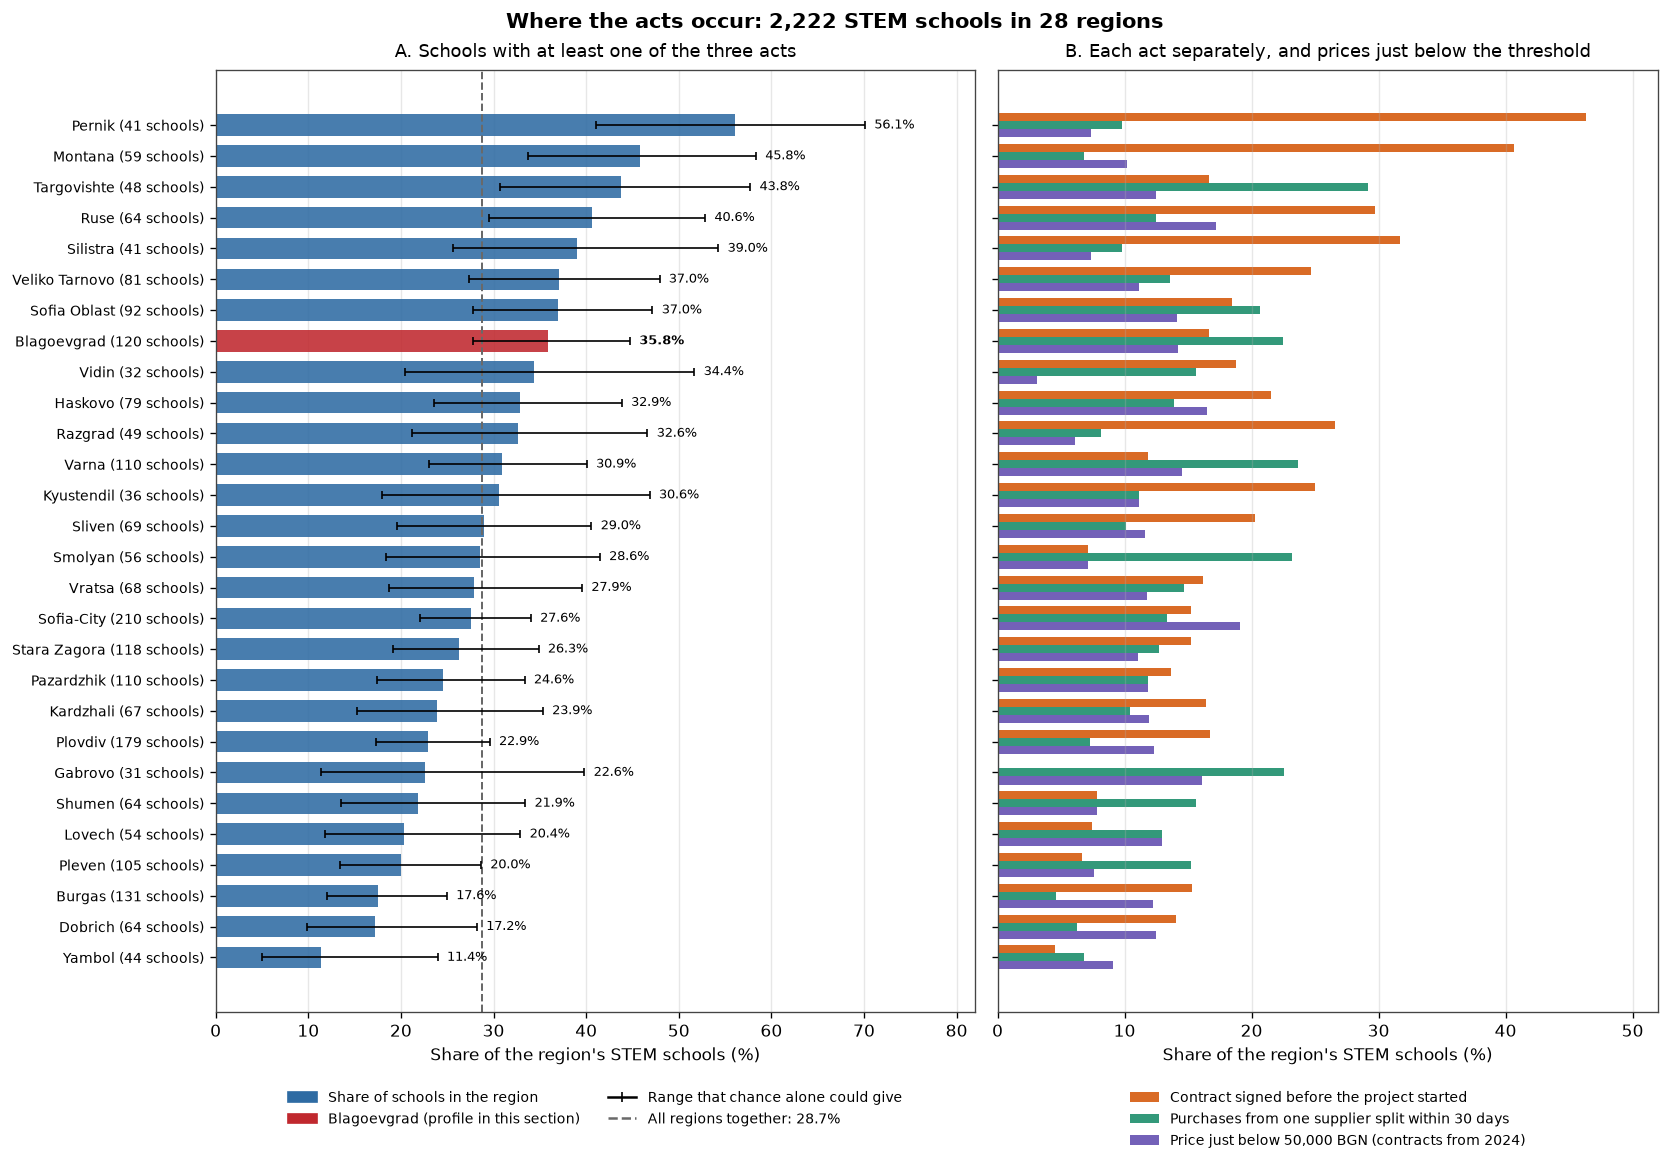

In [14]:
# Figure F2_2: share of STEM schools with the acts by region; every number in the figure is taken from this run.
from matplotlib.patches import Patch

ob_plot = ob_df.iloc[::-1].reset_index(drop=True).copy()
ob_plot["label"] = [f"{OBLAST_EN.get(r['oblast'], r['oblast'])} ({int(r['schools'])} schools)" for _, r in ob_plot.iterrows()]
y_pos = np.arange(len(ob_plot))
nat_l1 = float(sch_reg["flag_level1"].mean() * 100.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 9.6), sharey=True, gridspec_kw={"width_ratios": [1.15, 1.0]}, constrained_layout=True)

colors_l1 = ["#c0282e" if r["oblast"] == "Благоевград" else "#2e6ba3" for _, r in ob_plot.iterrows()]
ax1.barh(y_pos, ob_plot["level1_pct"], color=colors_l1, alpha=0.88, height=0.70, zorder=2)
ax1.errorbar(ob_plot["level1_pct"], y_pos,
             xerr=[ob_plot["level1_pct"] - ob_plot["level1_ci_low"], ob_plot["level1_ci_high"] - ob_plot["level1_pct"]],
             fmt="none", ecolor="black", elinewidth=1.0, capsize=2.5, zorder=3)
ax1.axvline(nat_l1, color="dimgray", linestyle="--", linewidth=1.2)
for idx_row, row in ob_plot.iterrows():
    ax1.text(row["level1_ci_high"] + 1.0, idx_row, f"{row['level1_pct']:.1f}%", va="center", ha="left", fontsize=7.8,
             fontweight="bold" if row["oblast"] == "Благоевград" else "normal")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(ob_plot["label"], fontsize=8.5)
ax1.set_xlabel("Share of the region's STEM schools (%)")
ax1.set_xlim(0, 82)
ax1.set_title("A. Schools with at least one of the three acts", fontsize=10.5, pad=8)
ax1.grid(axis="x", alpha=0.3)
ax1.legend(handles=[
    Patch(color="#2e6ba3", label="Share of schools in the region"),
    Patch(color="#c0282e", label="Blagoevgrad (profile in this section)"),
    plt.Line2D([], [], color="black", marker="|", linestyle="-", label="Range that chance alone could give"),
    plt.Line2D([], [], color="dimgray", linestyle="--", label=f"All regions together: {nat_l1:.1f}%"),
], loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=8.5, frameon=False)

bar_h = 0.26
ax2.barh(y_pos + bar_h, ob_plot["predated_pct"], height=bar_h, color="#d96b26", label="Contract signed before the project started")
ax2.barh(y_pos, ob_plot["split_30d_pct"], height=bar_h, color="#33997a", label="Purchases from one supplier split within 30 days")
ax2.barh(y_pos - bar_h, ob_plot["bunching_50k_pct"], height=bar_h, color="#7361b8", label="Price just below 50,000 BGN (contracts from 2024)")
ax2.set_xlabel("Share of the region's STEM schools (%)")
ax2.set_xlim(0, 52)
ax2.set_title("B. Each act separately, and prices just below the threshold", fontsize=10.5, pad=8)
ax2.grid(axis="x", alpha=0.3)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=1, fontsize=8.5, frameon=False)

fig.suptitle(f"Where the acts occur: {len(sch_reg):,} STEM schools in {len(ob_df)} regions", fontsize=12.5, fontweight="bold")
fig.savefig(FIG_DIR / "F2_2_indicator_share_by_region.png", dpi=300, bbox_inches="tight")
plt.show()